# Learning — Laboratorio 10

Semilla aleatoria: **42**. Ejecutar desde la carpeta del proyecto (con `imagenes/`). Las salidas se guardan en `figuras/` y `resultados/`.

**Parte 1:** Grad-CAM desde cero y CAM sobre ResNet-18. **Parte 2:** SHAP sobre German Credit. **Parte 3:** LIME desde cero y contrafactuales sobre German Credit. **Parte 4:** validación de Grad-CAM (deletion/insertion y aleatorización en cascada).

# Parte 1 — Task 1: Grad-CAM y CAM (ResNet-18)

In [1]:
import json
from pathlib import Path

import matplotlib
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import models, transforms

import matplotlib.pyplot as plt
import matplotlib.patches as patches

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DIR = Path.cwd()
(DIR / "figuras").mkdir(exist_ok=True)
(DIR / "resultados").mkdir(exist_ok=True)

## Task 1.1 — Modelo, imágenes y preprocesamiento
ResNet-18 preentrenado (ImageNet) en modo evaluación. Preprocesamiento: Resize(256) → CenterCrop(224) → normalización por canal.
Las imágenes (b) y (c) se recortan antes del preprocesamiento para que los objetos no queden cortados por el recorte central.
El recuadro del sofá se define en la imagen original y se transforma a coordenadas de 224×224.

In [2]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights).eval()
CATS = weights.meta["categories"]
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

geom = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
to_input = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
GRAY = 0.5  # "gris medio" en el espacio de pixeles [0, 1], antes de normalizar

# La imagen (c) se recorta antes del preprocesamiento estandar para que el sofa
# quede dentro del recorte central de 224x224 (el original es muy apaisado).
sofa = Image.open(DIR / "imagenes/img_c_sofa_original.jpg").convert("RGB")
sofa.crop((160, 0, 640, 427)).save(DIR / "imagenes/img_c_sofa.jpg", quality=95)
# Igual para (b): recorte cuadrado previo para que el gato (borde izquierdo) y el perro
# sobrevivan al recorte central de 224x224.
Image.open(DIR / "imagenes/img_b_gato_perro_original.jpg").convert("RGB").crop((85, 0, 725, 640)).save(
    DIR / "imagenes/img_b_gato_perro.jpg", quality=95)

IMAGES = {
    "a": ("imagenes/img_a_golden.jpg", "(a) Objeto centrado"),
    "b": ("imagenes/img_b_gato_perro.jpg", "(b) Dos objetos"),
    "c": ("imagenes/img_c_sofa.jpg", "(c) Fuera de contexto"),
}
crop = {}   # imagen 224x224 en [0,1], tensor (3,224,224)
for k, (path, _) in IMAGES.items():
    img224 = geom(Image.open(DIR / path).convert("RGB"))
    crop[k] = transforms.functional.to_tensor(img224)


def norm_input(img01):
    """(3,224,224) en [0,1] -> tensor normalizado (1,3,224,224)."""
    return transforms.functional.normalize(img01, MEAN, STD)[None]


# Recuadro del sofa en coordenadas de la imagen (c) pre-recortada (480x427)
# x en [330-160, 545-160], y en [253, 372]; se transforma al recorte 224x224.
sc = 256 / 427                       # factor de Resize(256) sobre el lado corto (427)
left, top = (480 * sc - 224) / 2, (427 * sc - 224) / 2
bx0, bx1 = (330 - 160) * sc - left, (545 - 160) * sc - left
by0, by1 = 253 * sc - top, 372 * sc - top
BBOX = [int(round(bx0)), int(round(by0)), int(round(bx1)), int(round(by1))]  # x0,y0,x1,y1

## Task 1.2 — Grad-CAM desde cero
Sea $A^k_{ij}$ la activación de `layer4` (512 canales de 7×7) y $y^c$ el **logit** de la clase $c$ (antes del softmax):

$$\alpha_k^c=\frac1Z\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\qquad L^c=\mathrm{ReLU}\Big(\sum_k\alpha_k^c A^k\Big)$$

El mapa $L^c$ (7×7) se amplía a 224×224 con interpolación bilineal y se normaliza con mínimo y máximo.

In [3]:
store = {}
model.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("A", o))               # A^k_ij
model.layer4.register_full_backward_hook(lambda m, gi, go: store.__setitem__("G", go[0]))   # dy^c/dA


def gradcam(x, c):
    """Devuelve alpha_k^c, L^c (7x7, con y sin ReLU), mapa 224x224 normalizado, A y logits."""
    model.zero_grad()
    logits = model(x)
    logits[0, c].backward()                       # se retropropaga el LOGIT y^c, no el softmax
    A = store["A"][0].detach()                    # (512,7,7)
    G = store["G"][0].detach()                    # (512,7,7)
    alpha = G.mean(dim=(1, 2))                    # alpha_k^c = promedio espacial del gradiente
    raw = (alpha[:, None, None] * A).sum(0)       # sum_k alpha_k A^k   (sin ReLU)
    L = F.relu(raw)                               # L^c = ReLU(sum_k alpha_k A^k)
    up = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    up = (up - up.min()) / (up.max() - up.min() + 1e-12)   # normalizacion min-max
    return dict(alpha=alpha, raw=raw, L=L, up=up, A=A, logits=logits.detach()[0])


def minmax(m):
    return (m - m.min()) / (m.max() - m.min() + 1e-12)

## Tasks 1.1, 1.3 y 1.4 — ejecución sobre las tres imágenes
- **1.3 (CAM):** $M^c_{ij}=\sum_k w^c_k A^k_{ij}$, y la descomposición $\frac1Z\sum_{ij}M^c_{ij}+b_c=y^c$ con $Z=49$.
- **Relación con Grad-CAM:** como $\partial y^c/\partial A^k_{ij}=w^c_k/Z$, se tiene $\alpha^c_k=w^c_k/Z$ y por tanto $Z\cdot L^c_{\text{sin ReLU}}=M^c$.
- **1.4:** $\alpha$ vs. $w/Z$ (imagen a), IoU del 20 % superior entre las dos clases (imagen b), masa dentro del recuadro y prueba causal con gris (imagen c).

In [4]:
R = {"seed": SEED, "bbox_c_224": BBOX}
CAT_IDX = set(range(281, 286))          # gatos domesticos de ImageNet
DOG_IDX = set(range(151, 269))          # perros de ImageNet
W, bias = model.fc.weight.detach(), model.fc.bias.detach()
Z = 49
res = {}

for k in IMAGES:
    x = norm_input(crop[k])
    with torch.no_grad():
        probs = F.softmax(model(x), 1)[0]
    top5 = probs.topk(5)
    c = int(top5.indices[0])
    cls = {"top1": c}
    if k == "b":   # clase del segundo objeto: la mejor del grupo (gato/perro) que no contiene a top-1
        other = DOG_IDX if c in CAT_IDX else CAT_IDX
        cls["second"] = max(other, key=lambda i: probs[i].item())
    r = {"top5": [(CATS[int(i)], int(i), float(p)) for p, i in zip(top5.values, top5.indices)],
         "classes": {n: (CATS[i], i, float(probs[i])) for n, i in cls.items()}}

    gc = {n: gradcam(x, i) for n, i in cls.items()}
    res[k] = dict(x=x, probs=probs, cls=cls, gc=gc)

    # ---------------- Task 1.3  CAM, descomposicion y relacion con Grad-CAM ------------- #
    g = gc["top1"]
    A = g["A"]
    M = (W[c][:, None, None] * A).sum(0)                       # M_ij^c = sum_k w_k^c A_ij^k
    logit = float(g["logits"][c])
    recon = float(M.mean() + bias[c])                          # (1/Z) sum_ij M_ij + b_c
    err_decomp = abs(recon - logit)
    L_nr = g["raw"]                                            # L^c sin ReLU ni normalizacion
    err_gradcam_M = float((Z * L_nr - M).abs().max())          # |Z L^c - M^c| maximo sobre 49 posiciones
    err_norm = float((minmax(F.relu(L_nr)) - minmax(F.relu(M))).abs().max())
    r["task13"] = dict(logit=logit, recon=recon, err_decomp=err_decomp,
                       err_ZL_vs_M=err_gradcam_M, err_relu_minmax=err_norm,
                       M_range=[float(M.min()), float(M.max())])
    res[k]["M"] = M

    # ---------------- Task 1.4a (solo imagen a) ----------------------------------------- #
    if k == "a":
        wk = W[c]
        idx = wk.topk(5).indices
        rows = []
        for j in idx.tolist():
            a_j, t_j = float(g["alpha"][j]), float(wk[j] / Z)
            rows.append(dict(canal=j, w=float(wk[j]), alpha=a_j, w_sobre_Z=t_j,
                             err_rel=abs(a_j - t_j) / abs(t_j)))
        r["task14a"] = rows
        r["task14a_all"] = dict(max_abs_err=float((g["alpha"] - wk / Z).abs().max()),
                                max_rel_err=float(((g["alpha"] - wk / Z).abs() / (wk / Z).abs()).max()),
                                dtype=str(g["alpha"].dtype))

    # ---------------- Task 1.4b (solo imagen b) ----------------------------------------- #
    if k == "b":
        u1, u2 = gc["top1"]["up"].flatten(), gc["second"]["up"].flatten()
        n20 = int(np.ceil(0.2 * u1.numel()))
        s1 = set(torch.argsort(u1, descending=True, stable=True)[:n20].tolist())
        s2 = set(torch.argsort(u2, descending=True, stable=True)[:n20].tolist())
        # Variante a nivel de celda 7x7 (top 20% = 10 de 49 celdas) como complemento
        c1, c2 = gc["top1"]["L"].flatten(), gc["second"]["L"].flatten()
        t1 = set(torch.argsort(c1, descending=True, stable=True)[:10].tolist())
        t2 = set(torch.argsort(c2, descending=True, stable=True)[:10].tolist())
        r["task14b"] = dict(iou_224=len(s1 & s2) / len(s1 | s2), n_pix=n20,
                            iou_7x7=len(t1 & t2) / len(t1 | t2),
                            spearman_7x7=None)
        from scipy.stats import spearmanr
        r["task14b"]["spearman_7x7"] = float(spearmanr(c1.numpy(), c2.numpy())[0])

    # ---------------- Task 1.1 (c) y Task 1.4c ------------------------------------------ #
    if k == "c":
        x0, y0, x1, y1 = BBOX
        up = gc["top1"]["up"]
        inside = float(up[y0:y1, x0:x1].sum() / up.sum())
        area = (x1 - x0) * (y1 - y0) / 224 ** 2
        img_out = torch.full_like(crop[k], GRAY)              # fuera del recuadro -> gris
        img_out[:, y0:y1, x0:x1] = crop[k][:, y0:y1, x0:x1]
        img_in = crop[k].clone()                              # prueba complementaria: objeto -> gris
        img_in[:, y0:y1, x0:x1] = GRAY
        with torch.no_grad():
            p_full = float(probs[c])
            p_out = float(F.softmax(model(norm_input(img_out)), 1)[0, c])
            p_in = float(F.softmax(model(norm_input(img_in)), 1)[0, c])
            top_out = int(F.softmax(model(norm_input(img_out)), 1)[0].argmax())
            top_in = int(F.softmax(model(norm_input(img_in)), 1)[0].argmax())
        r["task14c"] = dict(bbox=BBOX, mass_inside=inside, area_fraction=area,
                            ratio=inside / area, p_full=p_full, p_bg_gray=p_out,
                            p_obj_gray=p_in, top_bg_gray=CATS[top_out], top_obj_gray=CATS[top_in])
        res[k]["img_out"], res[k]["img_in"] = img_out, img_in
    R[k] = r

# Task 1.4a (complemento): el mismo calculo en doble precision para ver el piso numerico
model.double()
xa = res["a"]["x"].double()
g64 = gradcam(xa, res["a"]["cls"]["top1"])
ca = res["a"]["cls"]["top1"]
w64 = model.fc.weight.detach()[ca]
rel64 = ((g64["alpha"] - w64 / Z).abs() / (w64 / Z).abs())
R["a"]["task14a_float64"] = dict(max_rel_err=float(rel64.max()), max_abs_err=float((g64["alpha"] - w64 / Z).abs().max()),
                                 top5_rel_err=[float(rel64[j]) for j in w64.topk(5).indices.tolist()])
model.float()

json.dump(R, open(DIR / "resultados/task1.json", "w"), indent=2, ensure_ascii=False)

## Figuras de Task 1

In [5]:
def overlay(ax, img01, heat, title):
    ax.imshow(img01.permute(1, 2, 0).numpy())
    ax.imshow(heat.numpy(), cmap="jet", alpha=0.5, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")


panels = [("a", "top1"), ("b", "top1"), ("b", "second"), ("c", "top1")]
fig, axs = plt.subplots(2, 4, figsize=(12, 6.6))
for j, (k, n) in enumerate(panels):
    cidx = res[k]["cls"][n]
    axs[0, j].imshow(crop[k].permute(1, 2, 0).numpy())
    axs[0, j].set_title(f"({k}) entrada 224x224", fontsize=8)
    axs[0, j].axis("off")
    if k == "c":
        x0, y0, x1, y1 = BBOX
        axs[0, j].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
    overlay(axs[1, j], crop[k], res[k]["gc"][n]["up"],
            f"Grad-CAM: {CATS[cidx][:24]}\np={float(res[k]['probs'][cidx]):.3f}")
plt.tight_layout(h_pad=2.5)
plt.savefig(DIR / "figuras/fig_gradcam.png", dpi=150)
plt.close()

# Figura de la prueba causal (imagen c)
fig, axs = plt.subplots(1, 3, figsize=(8.5, 3))
for ax, im, t in zip(axs, [crop["c"], res["c"]["img_out"], res["c"]["img_in"]],
                     [f"original  p={R['c']['task14c']['p_full']:.3f}",
                      f"fondo gris  p={R['c']['task14c']['p_bg_gray']:.3f}",
                      f"objeto gris  p={R['c']['task14c']['p_obj_gray']:.3f}"]):
    ax.imshow(im.permute(1, 2, 0).numpy())
    ax.set_title(t, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(DIR / "figuras/fig_causal.png", dpi=150)
plt.close()

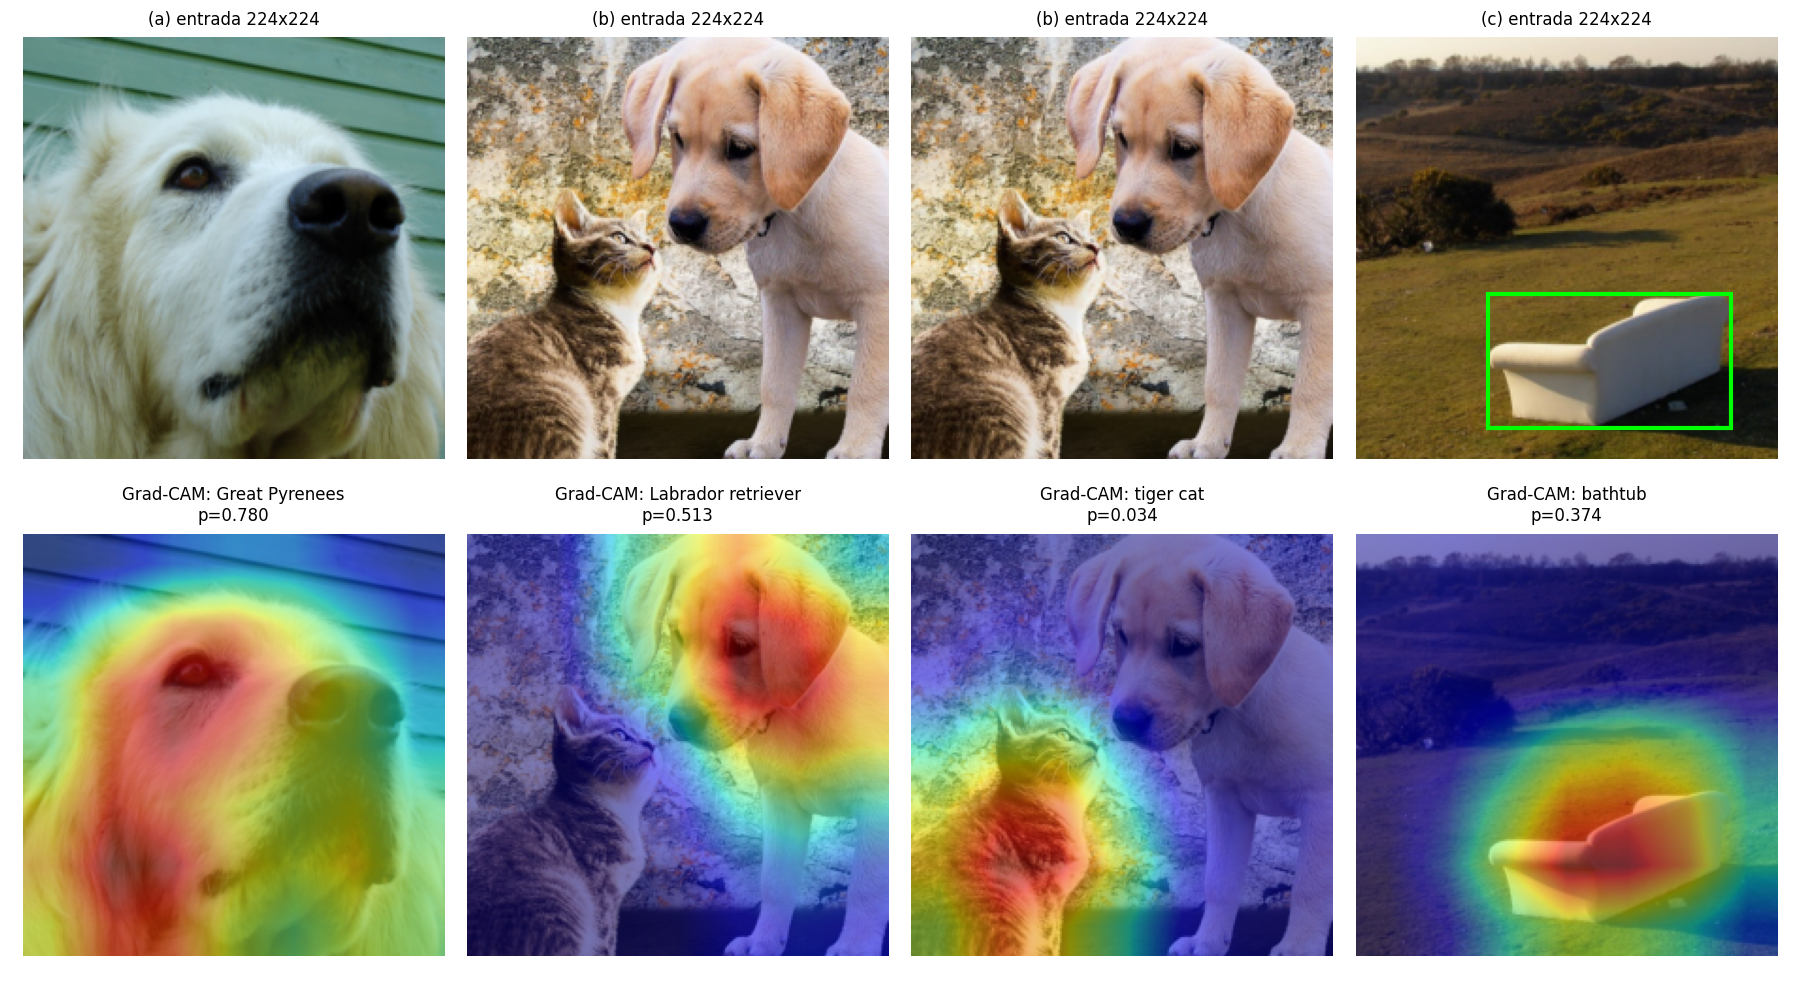

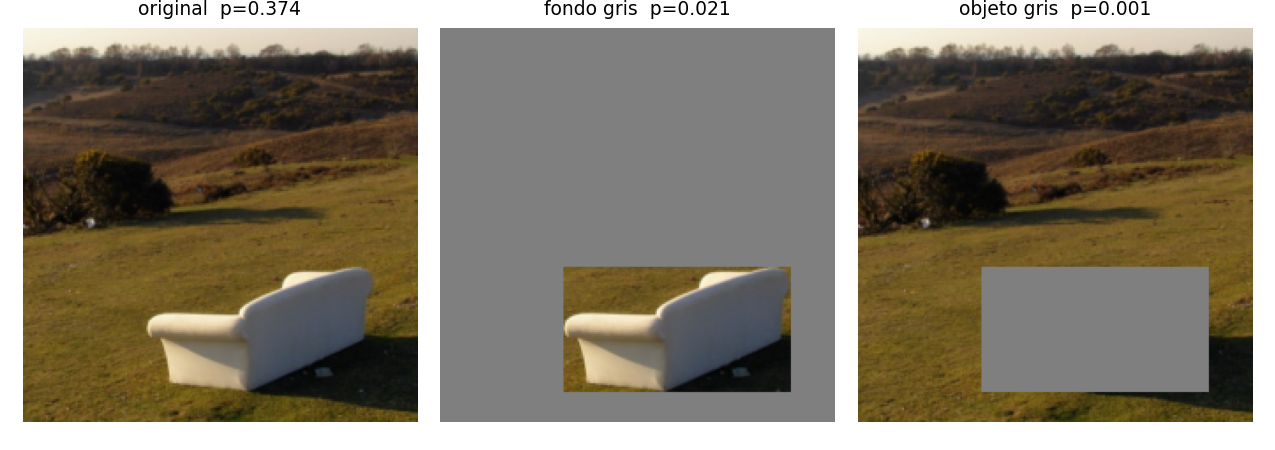

In [6]:
from IPython.display import Image, display
for f in ["fig_gradcam.png", "fig_causal.png"]:
    display(Image(filename=str(DIR / "figuras" / f)))

## Resumen numérico de Task 1

In [7]:
import pprint
for k in 'abc':
    print(k, 'top5:', [(n, round(p, 3)) for n, _, p in R[k]['top5']])
    print('   1.3:', R[k]['task13'])
print('1.4a (5 canales):', R['a']['task14a'])
print('1.4a (todos):', R['a']['task14a_all'], R['a']['task14a_float64'])
print('1.4b:', R['b']['task14b'])
print('1.4c:', R['c']['task14c'])

a top5: [('Great Pyrenees', 0.78), ('kuvasz', 0.076), ('golden retriever', 0.05), ('Samoyed', 0.024), ('malamute', 0.013)]
   1.3: {'logit': 13.243913650512695, 'recon': 13.243912696838379, 'err_decomp': 9.5367431640625e-07, 'err_ZL_vs_M': 5.7220458984375e-06, 'err_relu_minmax': 2.384185791015625e-07, 'M_range': [0.029170021414756775, 23.03831672668457]}
b top5: [('Labrador retriever', 0.513), ('Chesapeake Bay retriever', 0.066), ('tiger cat', 0.034), ('tabby', 0.023), ('beagle', 0.022)]
   1.3: {'logit': 10.702860832214355, 'recon': 10.702862739562988, 'err_decomp': 1.9073486328125e-06, 'err_ZL_vs_M': 3.814697265625e-06, 'err_relu_minmax': 1.1920928955078125e-07, 'M_range': [-3.4138400554656982, 36.47795104980469]}
c top5: [('bathtub', 0.374), ('tub', 0.369), ('bucket', 0.031), ('ashcan', 0.024), ('barrow', 0.017)]
   1.3: {'logit': 10.493219375610352, 'recon': 10.493219375610352, 'err_decomp': 0.0, 'err_ZL_vs_M': 7.62939453125e-06, 'err_relu_minmax': 2.384185791015625e-07, 'M_range':

# Parte 2 — Task 2: SHAP sobre German Credit

In [8]:
import json
import math
import time
import warnings
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import shap
from scipy.stats import rankdata, spearmanr
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
DIR = Path.cwd()
(DIR / "figuras").mkdir(exist_ok=True)
(DIR / "resultados").mkdir(exist_ok=True)
R = {"seed": SEED}
sigmoid = lambda z: 1 / (1 + np.exp(-z))

## Task 2.1 — German Credit y gradient boosting
`good`=1, `bad`=0; categóricas con `OrdinalEncoder` (**los códigos son arbitrarios**; se tratan como numéricos, limitación declarada en el informe).
Split 80/20 estratificado; 200 árboles, profundidad 3, semilla 42.

In [9]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw, y = datos.data.copy(), (datos.target == "good").astype(int).to_numpy()   # good=1, bad=0
cat_cols = [c for c in X_raw.columns if str(X_raw[c].dtype) in ("category", "object")]
num_cols = [c for c in X_raw.columns if c not in cat_cols]
enc = OrdinalEncoder(dtype=float)       # codigos arbitrarios (se tratan como numericos)
X = X_raw.copy()
X[cat_cols] = enc.fit_transform(X_raw[cat_cols])
X = X.astype(float)
feats = list(X.columns)
d = len(feats)
cat_labels = dict(zip(cat_cols, enc.categories_))
R["n"], R["n_num"], R["n_cat"] = len(X), len(num_cols), len(cat_cols)
R["prop_good"] = float(y.mean())

idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = X.values[idx_tr], X.values[idx_te], y[idx_tr], y[idx_te]

N_TREES, DEPTH = 200, 3


def fit(Xa, ya):
    return GradientBoostingClassifier(n_estimators=N_TREES, max_depth=DEPTH, random_state=SEED).fit(Xa, ya)


model = fit(Xtr, ytr)
f_raw = model.decision_function              # salida en log-odds
p_te = model.predict_proba(Xte)[:, 1]
R["t21"] = dict(acc=float(accuracy_score(yte, model.predict(Xte))), auc=float(roc_auc_score(yte, p_te)),
                n_train=len(idx_tr), n_test=len(idx_te))

bg_idx = rng.choice(len(Xtr), 100, replace=False)       # fondo de 100 instancias de entrenamiento
bg = Xtr[bg_idx]

## Task 2.2 — SHAP intervencional (log-odds)
- Eficiencia: $\phi_0+\sum_j\phi_j=f(x)$, con $\phi_0=\mathbb E_{\text{fondo}}[f]$.
- Importancia global: $I_j=\frac1N\sum_n|\phi^{(n)}_j|$, comparada con la importancia por permutación (AUC, 10 repeticiones) mediante Spearman.

In [10]:
expl = shap.TreeExplainer(model, data=bg, feature_perturbation="interventional", model_output="raw")
phi = expl.shap_values(Xte, check_additivity=False)
base = float(np.ravel(expl.expected_value)[0])
err_eff = np.abs(base + phi.sum(1) - f_raw(Xte))
R["t22a"] = dict(max_err=float(err_eff.max()), mean_err=float(err_eff.mean()))
R["t22b"] = dict(base_value=base, mean_logodds_bg=float(f_raw(bg).mean()), diff=abs(base - float(f_raw(bg).mean())))

I = np.abs(phi).mean(0)                                           # I_j = 1/N sum_n |phi_j^(n)|
perm = permutation_importance(model, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED)
Ip = perm.importances_mean
top = lambda v: [(feats[j], float(v[j])) for j in np.argsort(-v)[:5]]
R["t22c"] = dict(top_shap=top(I), top_perm=top(Ip), spearman=float(spearmanr(I, Ip)[0]),
                 I={feats[j]: float(I[j]) for j in range(d)}, perm={feats[j]: float(Ip[j]) for j in range(d)})


def decode(row):
    """Valores de una fila con las categoricas decodificadas (solo para mostrar)."""
    out = []
    for j, c in enumerate(feats):
        out.append(cat_labels[c][int(row[j])] if c in cat_labels else float(row[j]))
    return out


# clientes: p(good) mas cercana a 0.9 entre los > 0.8, y a 0.1 entre los < 0.2
cand_hi, cand_lo = np.where(p_te > 0.8)[0], np.where(p_te < 0.2)[0]
i_good = int(cand_hi[np.argmin(np.abs(p_te[cand_hi] - 0.9))])
i_bad = int(cand_lo[np.argmin(np.abs(p_te[cand_lo] - 0.1))])
R["clients"] = {"good": i_good, "bad": i_bad, "n_hi": int(len(cand_hi)), "n_lo": int(len(cand_lo))}
for name, i in [("good", i_good), ("bad", i_bad)]:
    o = np.argsort(-np.abs(phi[i]))[:3]
    R["clients"][name + "_info"] = dict(
        p=float(p_te[i]), f=float(f_raw(Xte[i:i + 1])[0]), y_true=int(yte[i]),
        top3=[(feats[j], decode(Xte[i])[j], float(phi[i, j])) for j in o])
    ex = shap.Explanation(values=phi[i], base_values=base, data=np.array(decode(Xte[i]), dtype=object),
                          feature_names=feats)
    plt.figure()
    shap.plots.waterfall(ex, max_display=10, show=False)
    plt.gcf().set_size_inches(7, 4.2)
    plt.title(f"p(good)={p_te[i]:.3f}", fontsize=10)
    plt.savefig(DIR / f"figuras/fig_waterfall_{name}.png", dpi=150, bbox_inches="tight")
    plt.close("all")

plt.figure()
shap.plots.beeswarm(shap.Explanation(values=phi, base_values=np.full(len(phi), base), data=Xte, feature_names=feats),
                    max_display=12, show=False)
plt.gcf().set_size_inches(7, 4.8)
plt.savefig(DIR / "figuras/fig_beeswarm.png", dpi=150, bbox_inches="tight")
plt.close("all")

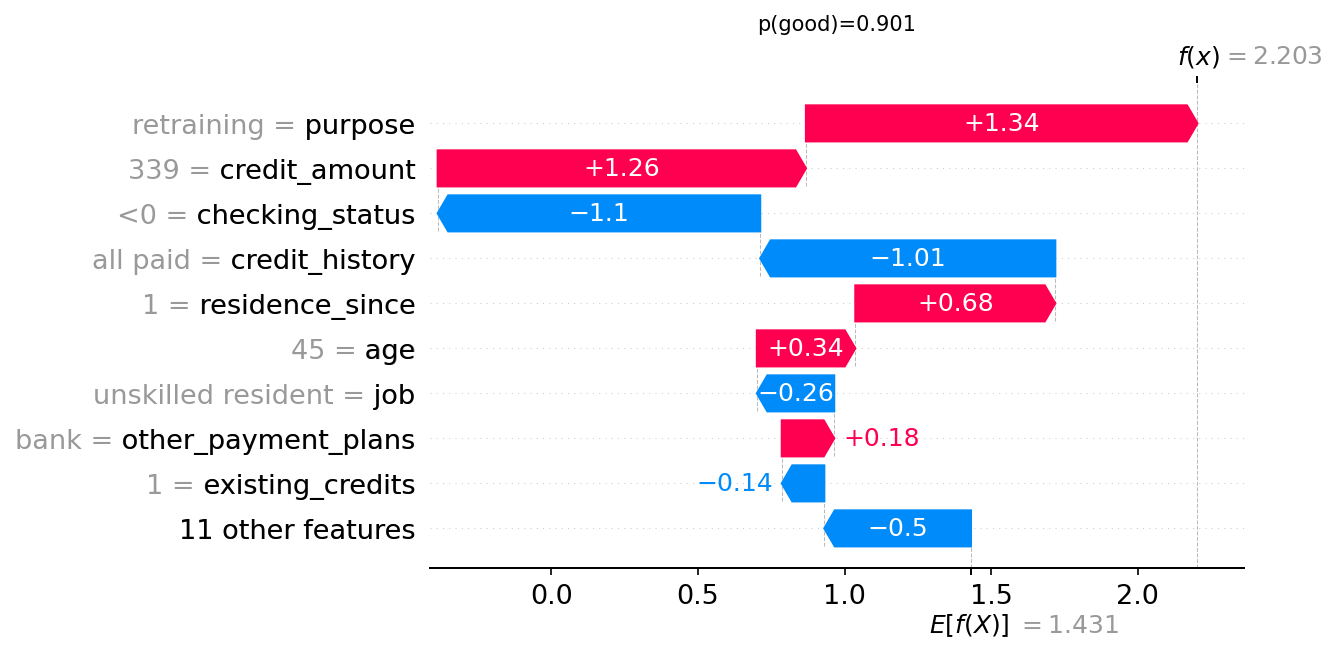

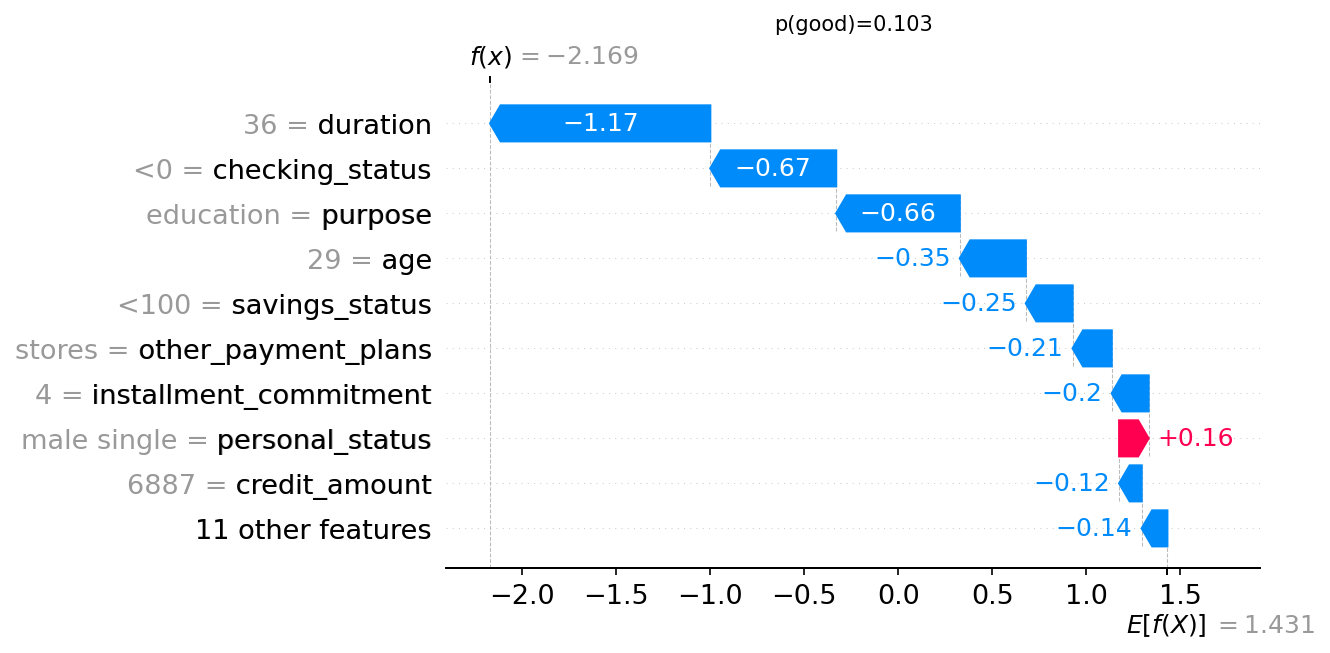

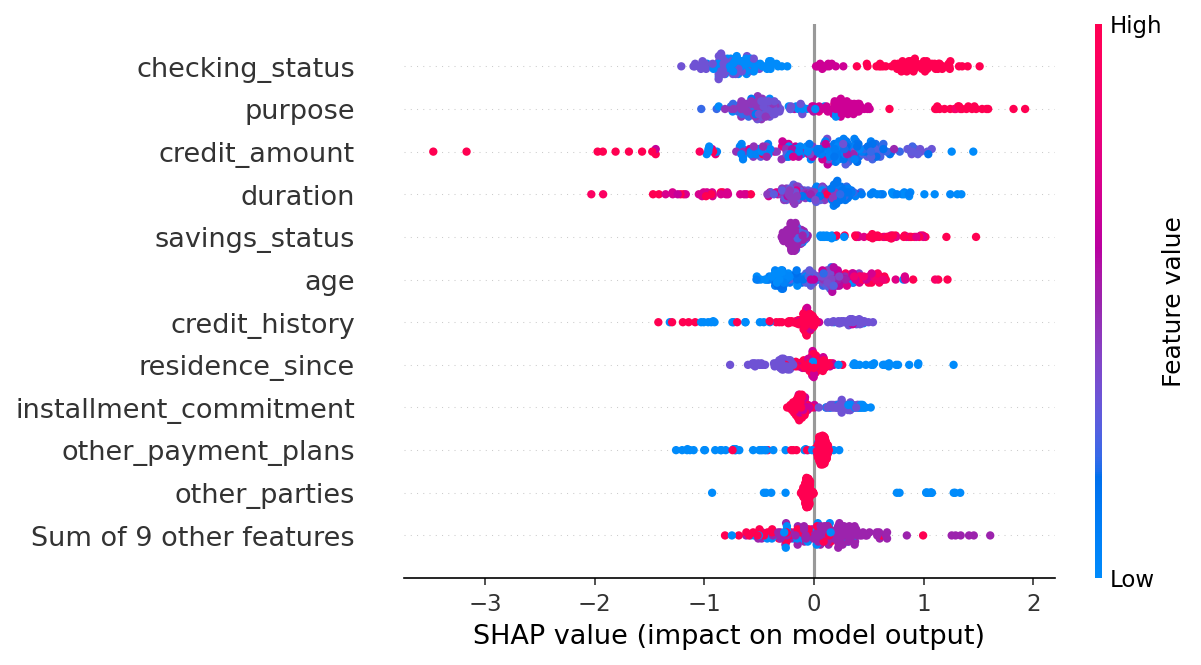

In [11]:
from IPython.display import Image, display
for f in ["fig_waterfall_good.png", "fig_waterfall_bad.png", "fig_beeswarm.png"]:
    display(Image(filename=str(DIR / "figuras" / f)))

## Task 2.3 — Variable redundante
$x_{\text{dup}}=x+0.05\,\sigma_x\,\epsilon$, $\epsilon\sim\mathcal N(0,1)$. Se compara SHAP intervencional (con fondo) y `tree_path_dependent`.

In [12]:
num_idx = [feats.index(c) for c in num_cols]
j0 = max(num_idx, key=lambda j: I[j])
sx = Xtr[:, j0].std()
rng_noise = np.random.default_rng(SEED)
x_dup = X.values[:, j0] + 0.05 * sx * rng_noise.standard_normal(len(X))       # x + 0.05 sigma_x eps
X21 = np.column_stack([X.values, x_dup])
feats21 = feats + [feats[j0] + "_copia"]
Xtr21, Xte21 = X21[idx_tr], X21[idx_te]
model21 = fit(Xtr21, ytr)
bg21 = Xtr21[bg_idx]
cfg = {}
e_int = shap.TreeExplainer(model21, data=bg21, feature_perturbation="interventional", model_output="raw")
e_tp = shap.TreeExplainer(model21, feature_perturbation="tree_path_dependent", model_output="raw")
for name, e in [("intervencional", e_int), ("tree_path_dependent", e_tp)]:
    ph = e.shap_values(Xte21, check_additivity=False)
    cfg[name] = dict(orig=float(np.abs(ph[:, j0]).mean()), copia=float(np.abs(ph[:, d]).mean()),
                     suma=float(np.abs(ph[:, j0] + ph[:, d]).mean()),
                     corr_phi=float(np.corrcoef(ph[:, j0], ph[:, d])[0, 1]))
R["t23"] = dict(var=feats[j0], I_sin_copia=float(I[j0]), corr_x_copia=float(np.corrcoef(Xte[:, j0], Xte21[:, d])[0, 1]),
                auc21=float(roc_auc_score(yte, model21.predict_proba(Xte21)[:, 1])), configs=cfg)

## Task 2.4 — KernelSHAP vs TreeSHAP
KernelSHAP con 2 000 muestras y fondos de 10, 50 y 100; error medio frente a TreeSHAP intervencional con el mismo fondo, y tiempo.

In [13]:
sel = rng.choice(len(Xte), 10, replace=False)
Xk = Xte[sel]
rows = []
for nb in (10, 50, 100):
    bgk = bg[:nb]
    t0 = time.perf_counter()
    ks = shap.KernelExplainer(f_raw, bgk, link="identity")
    pk = ks.shap_values(Xk, nsamples=2000, l1_reg=0, silent=True)
    t_kernel = time.perf_counter() - t0
    t0 = time.perf_counter()
    tr = shap.TreeExplainer(model, data=bgk, feature_perturbation="interventional", model_output="raw")
    pt = tr.shap_values(Xk, check_additivity=False)
    t_tree = time.perf_counter() - t0
    rows.append(dict(bg=nb, mae=float(np.abs(pk - pt).mean()), max_err=float(np.abs(pk - pt).max()),
                     t_kernel=t_kernel, t_kernel_inst=t_kernel / len(Xk), t_tree=t_tree,
                     eff_err=float(np.abs(ks.expected_value + pk.sum(1) - f_raw(Xk)).max())))
R["t24"] = rows

## Task 2.5 — Shapley exacto escrito a mano
$$v(S)=\frac1{|B|}\sum_{b\in B}f(x_S,b_{\bar S}),\qquad
\phi_i=\sum_{S\subseteq N\setminus\{i\}}\frac{|S|!\,(n-|S|-1)!}{n!}\big[v(S\cup\{i\})-v(S)\big]$$
Se enumeran las $2^6=64$ coaliciones y se verifica la eficiencia $\sum_i\phi_i=v(N)-v(\emptyset)$.

In [14]:
six = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
six_idx = [feats.index(c) for c in six]
n6 = len(six)
Xtr6, Xte6 = Xtr[:, six_idx], Xte[:, six_idx]
model6 = fit(Xtr6, ytr)
bg6 = Xtr6[np.random.default_rng(SEED).choice(len(Xtr6), 50, replace=False)]
f6 = model6.decision_function
R["t25_model"] = dict(acc=float(accuracy_score(yte, model6.predict(Xte6))),
                      auc=float(roc_auc_score(yte, model6.predict_proba(Xte6)[:, 1])))


def v_all(x, bg_, f):
    """v(S) para las 2^n coaliciones: promedio de f sobre el fondo con x_S fijo y el resto del fondo."""
    n, nb = len(x), len(bg_)
    masks = ((np.arange(1 << n)[:, None] >> np.arange(n)) & 1).astype(bool)      # (2^n, n): mascara de S
    Z = np.where(masks[:, None, :], x[None, None, :], bg_[None, :, :])            # (2^n, nb, n)
    return f(Z.reshape(-1, n)).reshape(1 << n, nb).mean(1)


def shapley_exact(v, n):
    """phi_i = sum_{S subset N\\{i}} |S|!(n-|S|-1)!/n! * [v(S u {i}) - v(S)]."""
    phi_ = np.zeros(n)
    for i in range(n):
        for S in range(1 << n):
            if S & (1 << i):
                continue
            s = bin(S).count("1")
            w = math.factorial(s) * math.factorial(n - s - 1) / math.factorial(n)
            phi_[i] += w * (v[S | (1 << i)] - v[S])
    return phi_


sel5 = rng.choice(len(Xte6), 5, replace=False)
e6 = shap.TreeExplainer(model6, data=bg6, feature_perturbation="interventional", model_output="raw")
mine, ref, eff = [], [], []
for i in sel5:
    v = v_all(Xte6[i], bg6, f6)
    ph = shapley_exact(v, n6)
    mine.append(ph)
    ref.append(e6.shap_values(Xte6[i:i + 1], check_additivity=False)[0])
    eff.append(abs(ph.sum() - (v[-1] - v[0])))          # v[-1]=v(N)=f(x), v[0]=v(empty)=media de f en el fondo
mine, ref = np.array(mine), np.array(ref)
R["t25"] = dict(idx=[int(i) for i in sel5], max_err_vs_tree=float(np.abs(mine - ref).max()),
                max_eff_err=float(max(eff)), phi_mine_0=mine[0].tolist(), phi_tree_0=ref[0].tolist(),
                v_N_minus_v_empty_0=float(v_all(Xte6[sel5[0]], bg6, f6)[-1] - v_all(Xte6[sel5[0]], bg6, f6)[0]))

## Task 2.6 — Cálculos de apoyo
(a) efecto en probabilidad $\sigma(\phi_0+\phi_j)-\sigma(\phi_0)$; (b) ranking SHAP vs permutación; (d) costos de cómputo.

In [15]:
# (a) cliente rechazado: efecto individual en probabilidad
i = i_bad
p_x, p0 = float(sigmoid(f_raw(Xte[i:i + 1])[0])), float(sigmoid(base))
eff_j = sigmoid(base + phi[i]) - sigmoid(base)
order = np.argsort(-np.abs(eff_j))
R["t26a"] = dict(p_x=p_x, p0=p0, sum_effects=float(eff_j.sum()), diff=p_x - p0,
                 top_effects=[(feats[j], float(eff_j[j])) for j in order[:5]])

# (b) variable con mayor diferencia de posicion entre rankings
rk_s, rk_p = rankdata(-I), rankdata(-Ip)
jdiff = int(np.argmax(np.abs(rk_s - rk_p)))
Xdf = pd.DataFrame(Xte, columns=feats)
corr_s = Xdf.corr(method="spearman")[feats[jdiff]].drop(feats[jdiff])
cs = corr_s.reindex(corr_s.abs().sort_values(ascending=False).index)[:4]
perm_tr = permutation_importance(model, Xtr, ytr, scoring="roc_auc", n_repeats=10, random_state=SEED)
phi_tr = expl.shap_values(Xtr, check_additivity=False)
R["t26b_train"] = dict(perm_train=float(perm_tr.importances_mean[jdiff]), perm_train_std=float(perm_tr.importances_std[jdiff]),
                       I_train=float(np.abs(phi_tr[:, jdiff]).mean()),
                       auc_train=float(roc_auc_score(ytr, model.predict_proba(Xtr)[:, 1])),
                       spearman_phi_x=float(spearmanr(phi[:, jdiff], Xte[:, jdiff])[0]))
R["t26b"] = dict(var=feats[jdiff], rank_shap=int(rk_s[jdiff]), rank_perm=int(rk_p[jdiff]),
                 I=float(I[jdiff]), perm=float(Ip[jdiff]), perm_std=float(perm.importances_std[jdiff]),
                 top_corr=[(k, float(v)) for k, v in cs.items()],
                 ranks={feats[j]: (int(rk_s[j]), int(rk_p[j])) for j in range(d)})

# (d) costos
t100 = []
for _ in range(300):
    t0 = time.perf_counter()
    f_raw(Xte[:100])
    t100.append(time.perf_counter() - t0)
t100 = float(np.median(t100))
year = 365.25 * 24 * 3600
R["t26d"] = dict(t_pred_100=t100, t_exact_20=t100 * 2 ** 20, t_exact_20_h=t100 * 2 ** 20 / 3600,
                 t_kernel_inst_100=rows[-1]["t_kernel_inst"],
                 evals_kernel=2000 * 100, evals_exact=2 ** 20 * 100,
                 years_60=2 ** 60 * 1e-6 / year)

json.dump(R, open(DIR / "resultados/task2.json", "w"), indent=2, ensure_ascii=False)

## Resumen numérico de Task 2

In [16]:
for k in ['t21','t22a','t22b','t23','t24','t25_model','t25','t26a','t26b_train','t26d']:
    print(k, R[k])
print('t22c top SHAP:', R['t22c']['top_shap'])
print('t22c top perm:', R['t22c']['top_perm'], 'spearman', R['t22c']['spearman'])

t21 {'acc': 0.775, 'auc': 0.7649999999999999, 'n_train': 800, 'n_test': 200}
t22a {'max_err': 9.721730620526614e-08, 'mean_err': 1.4483257113062642e-08}
t22b {'base_value': 1.4307421474966338, 'mean_logodds_bg': 1.4307421474966338, 'diff': 0.0}
t23 {'var': 'credit_amount', 'I_sin_copia': 0.4902134791654752, 'corr_x_copia': 0.9988210681878069, 'auc21': 0.7658333333333334, 'configs': {'intervencional': {'orig': 0.5135348324321327, 'copia': 0.4347575010625995, 'suma': 0.5637930182543933, 'corr_phi': -0.2063333111955101}, 'tree_path_dependent': {'orig': 0.38131110739296276, 'copia': 0.39688405879376176, 'suma': 0.5586473945206931, 'corr_phi': -0.014738491494262367}}}
t24 [{'bg': 10, 'mae': 0.0026598954259095787, 'max_err': 0.011377158003633592, 't_kernel': 0.6067675000003874, 't_kernel_inst': 0.060676750000038734, 't_tree': 0.007271200000104727, 'eff_err': 1.1102230246251565e-15}, {'bg': 50, 'mae': 0.003479677248373183, 'max_err': 0.0173450440382988, 't_kernel': 2.6131734000000506, 't_kern

# Parte 3 — Task 3: LIME y contrafactuales (German Credit)
Se reutilizan el modelo, el fondo y los valores SHAP del Task 2 (mismo split, semilla 42). Resultados en `resultados/task3.json`.

## Task 3.1 — LIME tabular desde cero
Representación interpretable $z'\in\{0,1\}^{20}$: $z'_j=1$ conserva $x_j$; $z'_j=0$ lo reemplaza por un valor al azar de la columna $j$ de entrenamiento.

$$\pi_x(z)=\exp(-D^2/\sigma^2),\quad D^2=\#\{j: z'_j=0\},\quad \sigma=\sigma_{rel}\sqrt{d'},\ d'=20$$

$$w=(Z'^\top\Pi Z'+\lambda I)^{-1}Z'^\top\Pi\,y,\qquad R^2_w=1-\frac{\sum_n\pi_n(y_n-g_n)^2}{\sum_n\pi_n(y_n-\bar y_w)^2}$$

Parámetros: $N=5000$, $K=5$, $\lambda=1$, $\sigma_{rel}=0.75$. Salida explicada: $P(\text{good})$. **El intercepto no se penaliza** (su entrada en $\lambda I$ se pone en 0).

In [17]:
import itertools
from IPython.display import display

R3 = {"seed": SEED}

# Clientes: los dos del Task 2.2 + uno con p(good) en (0.45, 0.55), el mas cercano a 0.5
mid = np.where((p_te > 0.45) & (p_te < 0.55))[0]
i_mid = int(mid[np.argmin(np.abs(p_te[mid] - 0.5))])
CLIENTS = {"good(p>0.8)": i_good, "rechazado": i_bad, "limite(p~0.5)": i_mid}
R3["clients"] = {k: dict(idx=v, p=float(p_te[v])) for k, v in CLIENTS.items()}


def decode_val(j, v):
    """Valor de la variable j decodificado (categoria original) solo para mostrar."""
    return cat_labels[feats[j]][int(v)] if feats[j] in cat_labels else float(v)


def wridge(Zb, y_, pi, lam, penalize_intercept=False):
    """Solucion cerrada w = (Z'^T Pi Z' + lam I)^-1 Z'^T Pi y. Zb lleva una columna de unos al final.
    Por defecto el INTERCEPTO NO se penaliza (se anula su entrada en la diagonal de lam*I)."""
    P = np.eye(Zb.shape[1])
    if not penalize_intercept:
        P[-1, -1] = 0.0
    A = Zb.T @ (pi[:, None] * Zb) + lam * P                              # Z'^T Pi Z' + lam I
    return np.linalg.solve(A, Zb.T @ (pi * y_))                          # (...)^-1 Z'^T Pi y


def r2_w(y_, g, pi):
    """Fidelidad ponderada R^2_w = 1 - sum pi (y-g)^2 / sum pi (y-ybar_w)^2."""
    yb = (pi * y_).sum() / pi.sum()                                      # ybar_w
    return 1 - (pi * (y_ - g) ** 2).sum() / (pi * (y_ - yb) ** 2).sum()


def lime(x, N=5000, K=5, lam=1.0, sigma_rel=0.75, seed=0):
    """LIME tabular desde cero sobre el modelo del Task 2.1."""
    rng_l = np.random.default_rng(seed)
    Zp = (rng_l.random((N, d)) < 0.5).astype(float)                       # z' ~ Bernoulli(0.5)
    Rv = Xtr[rng_l.integers(0, len(Xtr), (N, d)), np.arange(d)]           # valor al azar por columna
    Z = np.where(Zp == 1, x[None, :], Rv)                                 # entrada z en el espacio original
    yv = model.predict_proba(Z)[:, 1]                                     # salida a explicar: P(good)
    D2 = (1 - Zp).sum(1)                                                  # D^2 = # variables ausentes
    sigma = sigma_rel * np.sqrt(d)                                        # sigma = sigma_rel * sqrt(d')
    pi = np.exp(-D2 / sigma ** 2)                                         # pi_x(z) = exp(-D^2/sigma^2)
    Zb = np.column_stack([Zp, np.ones(N)])
    w = wridge(Zb, yv, pi, lam)                                           # ajuste con las 20 variables
    r2_full = r2_w(yv, Zb @ w, pi)
    sel_ = np.argsort(-np.abs(w[:d]))[:K]                                 # K variables de mayor |w|
    Zs = np.column_stack([Zp[:, sel_], np.ones(N)])
    ws = wridge(Zs, yv, pi, lam)                                          # re-ajuste solo con ellas
    r2 = r2_w(yv, Zs @ ws, pi)
    Nef = pi.sum() ** 2 / (pi ** 2).sum()                                 # N_ef = (sum pi)^2 / sum pi^2
    return dict(w_full=w[:d], b_full=w[d], sel=sel_, w_sel=ws[:-1], b_sel=ws[-1], r2=float(r2),
                r2_full=float(r2_full), Nef=float(Nef), pi=pi)


R3["t31"] = {"penaliza_intercepto": False, "lam": 1.0, "N": 5000, "K": 5, "sigma_rel": 0.75}
lime_cache = {}
for name, i in CLIENTS.items():
    out = lime(Xte[i], seed=SEED)
    lime_cache[name] = out
    R3["t31"][name] = dict(
        idx=i, p=float(p_te[i]), r2_K5=out["r2"], r2_full20=out["r2_full"], intercepto=float(out["b_sel"]),
        coefs=[(feats[j], decode_val(j, Xte[i][j]), float(c)) for j, c in zip(out["sel"], out["w_sel"])])
    print(f"\n{name}  (idx={i}, p(good)={p_te[i]:.3f})  R2_w(K=5)={out['r2']:.4f}  "
          f"R2_w(20 var)={out['r2_full']:.4f}  intercepto={out['b_sel']:.4f}")
    display(pd.DataFrame(R3["t31"][name]["coefs"], columns=["variable", "valor del cliente", "coef w"]))


good(p>0.8)  (idx=95, p(good)=0.901)  R2_w(K=5)=0.3332  R2_w(20 var)=0.3590  intercepto=0.6649


,variable,valor del cliente,coef w
0,purpose,retraining,0.172144
1,credit_amount,339.0,0.152465
2,checking_status,<0,-0.114365
3,credit_history,all paid,-0.113036
4,residence_since,1.0,0.081596



rechazado  (idx=134, p(good)=0.103)  R2_w(K=5)=0.2080  R2_w(20 var)=0.2304  intercepto=0.6312


,variable,valor del cliente,coef w
0,duration,36.0,-0.150770
1,checking_status,<0,-0.125252
2,purpose,education,-0.102560
3,savings_status,<100,-0.065741
4,age,29.0,-0.058060



limite(p~0.5)  (idx=87, p(good)=0.504)  R2_w(K=5)=0.2791  R2_w(20 var)=0.2941  intercepto=0.6352


,variable,valor del cliente,coef w
0,checking_status,no checking,0.240831
1,duration,36.0,-0.153814
2,credit_amount,909.0,-0.106440
3,purpose,new car,-0.073586
4,age,36.0,0.043655


## Task 3.2 — Estabilidad de LIME (cliente rechazado)
20 corridas con semillas distintas por cada $N\in\{500,2000,5000\}$ y $\sigma_{rel}\in\{0.5,0.75,1.5\}$:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}\ \text{(promedio sobre los } \tbinom{20}{2}\text{ pares)},\qquad N_{ef}=\frac{(\sum_n\pi_n)^2}{\sum_n\pi_n^2}$$

In [18]:
xb = Xte[i_bad]
Ns, SIGS, RUNS, K = [500, 2000, 5000], [0.5, 0.75, 1.5], 20, 5


def jaccard_mean(sets):
    """Promedio de J(A,B) = |A n B| / |A u B| sobre todos los pares de corridas."""
    return float(np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(sets, 2)]))


def stability(N, sig, runs=RUNS, base_seed=1000):
    sets, nefs = [], []
    for r in range(runs):
        o = lime(xb, N=N, K=K, sigma_rel=sig, seed=base_seed + r)
        sets.append(set(o["sel"].tolist()))
        nefs.append(o["Nef"])
    return jaccard_mean(sets), float(np.mean(nefs))


jac = pd.DataFrame(index=[f"N={n}" for n in Ns], columns=[f"sig={s}" for s in SIGS], dtype=float)
nef = jac.copy()
for n in Ns:
    for s in SIGS:
        jac.loc[f"N={n}", f"sig={s}"], nef.loc[f"N={n}", f"sig={s}"] = stability(n, s)
R3["t32"] = dict(jaccard=jac.round(4).to_dict(), nef=nef.round(1).to_dict())
print("Jaccard promedio (K=5):")
display(jac.round(3))
print("N_ef promedio:")
display(nef.round(1))

Jaccard promedio (K=5):


,sig=0.5,sig=0.75,sig=1.5
N=500,0.651,0.615,0.607
N=2000,0.935,0.935,0.876
N=5000,1.000,1.000,1.000


N_ef promedio:


,sig=0.5,sig=0.75,sig=1.5
N=500,411.5,480.9,498.8
N=2000,1640.9,1922.6,1995.1
N=5000,4103.9,4807.1,4987.7


## Task 3.3 — LIME vs SHAP
(a) Spearman entre $|w|$ de LIME (ajuste con las 20 variables) y $|\phi|$ de SHAP del Task 2.2, y coincidencia del top 3. (b) $R^2_w$ del cliente rechazado para $K\in\{3,5,10,20\}$ (misma semilla, mismas muestras).

In [19]:
R3["t33a"] = {}
for name, i in CLIENTS.items():
    w_abs = np.abs(lime_cache[name]["w_full"])
    s_abs = np.abs(phi[i])
    t3_l, t3_s = np.argsort(-w_abs)[:3], np.argsort(-s_abs)[:3]
    R3["t33a"][name] = dict(spearman=float(spearmanr(w_abs, s_abs)[0]),
                            top3_lime=[feats[j] for j in t3_l], top3_shap=[feats[j] for j in t3_s],
                            overlap=len(set(t3_l) & set(t3_s)))
display(pd.DataFrame(R3["t33a"]).T)

R3["t33b"] = {}
for Kk in (3, 5, 10, 20):
    R3["t33b"][f"K={Kk}"] = lime(xb, K=Kk, seed=SEED)["r2"]       # misma semilla -> mismas muestras
display(pd.Series(R3["t33b"], name="R2_w (rechazado)").to_frame())

,spearman,top3_lime,top3_shap,overlap
good(p>0.8),0.902256,"[purpose, credit_amount, checking_status]","[purpose, credit_amount, checking_status]",3
rechazado,0.873684,"[duration, checking_status, purpose]","[duration, checking_status, purpose]",3
limite(p~0.5),0.869173,"[checking_status, duration, credit_amount]","[checking_status, duration, credit_amount]",3


,R2_w (rechazado)
K=3,0.179634
K=5,0.208035
K=10,0.227568
K=20,0.230433


## Task 3.4 — Contrafactuales por muestreo (cliente rechazado)
20 000 candidatos; cada uno cambia entre 1 y 3 variables **accionables** (`duration`, `credit_amount`, `installment_commitment`, `checking_status`, `savings_status`) con valores observados en entrenamiento. `age`, `personal_status` y `foreign_worker` son inmutables. Válido si $P(\text{good})\ge\theta=0.5$.

$$d(x,x')=\sum_{j\in\text{num}}\frac{|x_j-x'_j|}{\text{MAD}_j}+\sum_{j\in\text{cat}}\mathbb 1[x_j\ne x'_j]$$

($\text{MAD}_j$ = desviación absoluta mediana en entrenamiento; si es 0, desviación absoluta media.) Se elige el válido más cercano y luego dos más con conjunto de variables cambiadas distinto.

In [20]:
IMMUTABLE = ["age", "personal_status", "foreign_worker"]
ACTION = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]
act_idx = [feats.index(c) for c in ACTION]
num_set = set(feats.index(c) for c in num_cols)
MAD = np.zeros(d)
for j in range(d):
    col = Xtr[:, j]
    m = np.median(np.abs(col - np.median(col)))                     # MAD_j
    MAD[j] = m if m > 0 else np.mean(np.abs(col - col.mean()))      # si MAD=0 -> desviacion absoluta media
THETA, NCAND = 0.5, 20000


def distance(x, C):
    """d(x,x') = sum_num |xj-xj'|/MAD_j + sum_cat 1[xj != xj']."""
    dist = np.zeros(len(C))
    for j in range(d):
        dist += (np.abs(C[:, j] - x[j]) / MAD[j]) if j in num_set else (C[:, j] != x[j]).astype(float)
    return dist


def counterfactuals(x, max_changes=3, seed=SEED):
    rng_c = np.random.default_rng(seed)
    C = np.tile(x, (NCAND, 1))
    m = rng_c.integers(1, max_changes + 1, NCAND)                        # entre 1 y max_changes variables
    ranks = np.argsort(np.argsort(rng_c.random((NCAND, len(ACTION))), 1), 1)
    chosen = ranks < m[:, None]                                          # subconjunto aleatorio por candidato
    for a, j in enumerate(act_idx):
        vals = Xtr[rng_c.integers(0, len(Xtr), NCAND), j]                # valores observados en entrenamiento
        C[chosen[:, a], j] = vals[chosen[:, a]]
    changed = C != x[None, :]                                            # cambio efectivo (no solo sorteado)
    p = model.predict_proba(C)[:, 1]
    dist = distance(x, C)
    valid = (p >= THETA) & changed.any(1)
    picks, seen = [], set()
    for k in np.argsort(dist):                                           # de menor a mayor distancia
        if not valid[k]:
            continue
        key = frozenset(np.where(changed[k])[0].tolist())
        if key in seen:                                                  # conjunto de variables ya elegido
            continue
        seen.add(key)
        picks.append(int(k))
        if len(picks) == 3:
            break
    rows_cf = []
    for k in picks:
        ch = np.where(changed[k])[0]
        rows_cf.append(dict(vars=[feats[j] for j in ch], original=[decode_val(j, x[j]) for j in ch],
                            nuevo=[decode_val(j, C[k, j]) for j in ch], distancia=float(dist[k]), p_good=float(p[k])))
    return dict(max_changes=max_changes, validez=float(valid.mean()), n_validos=int(valid.sum()),
                proximidad_media=float(np.mean([r["distancia"] for r in rows_cf])) if rows_cf else None,
                dispersion_media=float(np.mean([len(r["vars"]) for r in rows_cf])) if rows_cf else None,
                proximidad_media_todos_validos=float(dist[valid].mean()) if valid.any() else None,
                dispersion_media_todos_validos=float(changed[valid].sum(1).mean()) if valid.any() else None,
                cfs=rows_cf)


cf = counterfactuals(xb, 3)
if not cf["cfs"]:                                    # regla del enunciado: si no hay validos -> maximo 5
    cf = counterfactuals(xb, 5)
    cf["nota"] = "Sin candidatos validos con max=3; se aumento a 5."
R3["t34"] = cf
R3["t34"]["p_original"] = float(p_te[i_bad])

tabla_cf = [dict(cf_n=n + 1, variable=v, original=o, nuevo=nv, distancia=round(r["distancia"], 3),
                 p_good=round(r["p_good"], 4))
            for n, r in enumerate(cf["cfs"]) for v, o, nv in zip(r["vars"], r["original"], r["nuevo"])]
print(f"p(good) original = {p_te[i_bad]:.4f}   max. variables cambiadas = {cf['max_changes']}")
display(pd.DataFrame(tabla_cf).set_index(["cf_n", "variable"]))
print(f"validez = {cf['validez']:.4f} ({cf['n_validos']} de {NCAND})   "
      f"proximidad media (3 CF) = {cf['proximidad_media']:.3f}   dispersion media (3 CF) = {cf['dispersion_media']:.2f}")
print(f"sobre todos los validos: proximidad media = {cf['proximidad_media_todos_validos']:.3f}   "
      f"dispersion media = {cf['dispersion_media_todos_validos']:.2f}")

p(good) original = 0.1026   max. variables cambiadas = 3


original             nuevo  distancia  p_good
cf_n variable                                                            
1    duration                   36.0              30.0      2.000  0.6428
     savings_status             <100  no known savings      2.000  0.6428
2    duration                   36.0              30.0      2.291  0.6428
     credit_amount            6887.0            6579.0      2.291  0.6428
     savings_status             <100  no known savings      2.291  0.6428
3    duration                   36.0              30.0      3.000  0.6561
     savings_status             <100  no known savings      3.000  0.6561
     installment_commitment      4.0               3.0      3.000  0.6561

validez = 0.0765 (1529 de 20000)   proximidad media (3 CF) = 2.430   dispersion media (3 CF) = 2.67
sobre todos los validos: proximidad media = 7.282   dispersion media = 2.54


## Task 3.5 — Cálculos de apoyo
- **(a)** $N$ para Jaccard $=0.9$ con $\sigma_{rel}=0.75$: el Jaccard satura en 1.0 con $N=5000$, así que 0.9 cae entre $N=500$ y $N=2000$. Se interpola en escala logarítmica, $J(N)\approx a+b\log N\Rightarrow N^*=\exp\!\big((0.9-a)/b\big)$, porque el ruido de los coeficientes baja como $1/\sqrt{N_{ef}}$ y $N_{ef}\propto N$. Se verifica con 20 corridas **nuevas** (otras semillas) en $N^*$ y en dos vecinos.
- **(b)** Cliente y variable con mayor diferencia de rango entre $|w|$ de LIME y $|\phi|$ de SHAP; sensibilidad a $\sigma_{rel}$ y perfil de $P(\text{good})$ al variar solo esa variable.
- **(d)** Variables de mayor $|\phi|$ del rechazado frente a las variables de los contrafactuales.

In [21]:
# (a) N necesario para Jaccard = 0.9 con sigma_rel = 0.75 (interpolacion en log N y verificacion)
S35, J_TARGET = "sig=0.75", 0.9
n_lo, n_hi = 500, 2000
j_lo, j_hi = jac.loc[f"N={n_lo}", S35], jac.loc[f"N={n_hi}", S35]
b_ = (j_hi - j_lo) / (np.log(n_hi) - np.log(n_lo))                   # J(N) ~ a + b log N
a_ = j_lo - b_ * np.log(n_lo)
n_star = int(round(np.exp((J_TARGET - a_) / b_), -1))                # N* = exp((0.9 - a) / b)
nef_ratio = nef.loc[f"N={n_hi}", S35] / n_hi                          # N_ef / N con sigma_rel = 0.75
verif = {}
for n in (int(round(0.75 * n_star, -1)), n_star, int(round(1.25 * n_star, -1))):
    j_, ne_ = stability(n, 0.75, base_seed=5000)                      # semillas distintas a las del 3.2
    verif[f"N={n}"] = dict(jaccard=j_, nef=ne_)
R3["t35a"] = dict(sigma_rel=0.75, puntos=dict(N=[n_lo, n_hi], jaccard=[float(j_lo), float(j_hi)]),
                  a=float(a_), b=float(b_), N_estimado=n_star, Nef_estimado=float(n_star * nef_ratio),
                  verificacion=verif)
print(f"(a) a={a_:.4f}  b={b_:.4f}  ->  N* = {n_star}  (N_ef* ~ {n_star * nef_ratio:.0f})")
display(pd.DataFrame(verif).T.round(4))

# (b) mayor discrepancia LIME vs SHAP: cliente y variable con mayor diferencia de rango
best = (None, None, -1)
for name, i in CLIENTS.items():
    rl, rs = rankdata(-np.abs(lime_cache[name]["w_full"])), rankdata(-np.abs(phi[i]))
    j = int(np.argmax(np.abs(rl - rs)))
    if abs(rl[j] - rs[j]) > best[2]:
        best = (name, j, abs(rl[j] - rs[j]))
cname, jd, _ = best
ci = CLIENTS[cname]
rs_shap = rankdata(-np.abs(phi[ci]))[jd]
sens = {}
for s in (0.25, 0.5, 0.75, 1.5):                                      # hipotesis de localidad: reducir sigma_rel
    ws_ = [lime(Xte[ci], sigma_rel=s, seed=2000 + r)["w_full"] for r in range(10)]
    wm = np.mean(ws_, 0)
    sens[f"sig={s}"] = dict(rank_lime=float(rankdata(-np.abs(wm))[jd]), coef=float(wm[jd]),
                            spearman=float(spearmanr(np.abs(wm), np.abs(phi[ci]))[0]))
# perfil: P(good) al variar SOLO esa variable en el cliente
grid = np.unique(np.quantile(Xtr[:, jd], np.linspace(0, 1, 40)))
Xg = np.tile(Xte[ci], (len(grid), 1))
Xg[:, jd] = grid
pg = model.predict_proba(Xg)[:, 1]
plt.figure(figsize=(5, 3.2))
plt.plot(grid, pg, "o-", ms=3)
plt.axvline(Xte[ci][jd], color="r", ls="--", label="valor del cliente")
plt.xlabel(feats[jd]); plt.ylabel("P(good)"); plt.title(f"Perfil: {cname}"); plt.legend()
plt.tight_layout(); plt.savefig(DIR / "figuras/fig_perfil_discrepancia.png", dpi=150); plt.close()
R3["t35b"] = dict(cliente=cname, variable=feats[jd], rank_shap=float(rs_shap), sens_sigma=sens,
                  valor_cliente=decode_val(jd, Xte[ci][jd]),
                  perfil=dict(x=grid.tolist(), p=pg.tolist()), phi=float(phi[ci][jd]))
print(f"\n(b) cliente={cname}  variable={feats[jd]}  valor={decode_val(jd, Xte[ci][jd])}  "
      f"phi={phi[ci][jd]:.4f}  rango SHAP={rs_shap:.0f}")
display(pd.DataFrame(sens).T.round(4))

# (d) variables con mayor |phi| del rechazado vs variables de los contrafactuales
top3 = np.argsort(-np.abs(phi[i_bad]))[:3]
info = []
for j in top3:
    g = np.unique(Xtr[:, j])
    Xg = np.tile(xb, (len(g), 1))
    Xg[:, j] = g
    pj = model.predict_proba(Xg)[:, 1]                                # P(good) cambiando SOLO la variable j
    k = int(np.argmax(pj))
    info.append(dict(var=feats[j], phi=float(phi[i_bad][j]), inmutable=feats[j] in IMMUTABLE,
                     accionable=feats[j] in ACTION, en_contrafactuales=any(feats[j] in r["vars"] for r in cf["cfs"]),
                     MAD=float(MAD[j]), p_max_cambiando_solo_esta=float(pj.max()),
                     valor_para_p_max=decode_val(j, g[k]),
                     costo_distancia_p_max=float(distance(xb, Xg[k:k + 1])[0])))
R3["t35d"] = info
print("\n(d) top 3 |phi| del rechazado:")
display(pd.DataFrame(info).set_index("var"))

json.dump(R3, open(DIR / "resultados/task3.json", "w"), indent=2, ensure_ascii=False, default=float)

(a) a=-0.8225  b=0.2312  ->  N* = 1720  (N_ef* ~ 1653)


,jaccard,nef
N=1290,0.8065,1239.2659
N=1720,0.9351,1652.6326
N=2150,0.9040,2065.9650



(b) cliente=good(p>0.8)  variable=existing_credits  valor=1.0  phi=-0.1450  rango SHAP=9


,rank_lime,coef,spearman
sig=0.25,12.0,-0.0086,0.9639
sig=0.5,13.0,-0.0141,0.9669
sig=0.75,14.0,-0.0138,0.9609
sig=1.5,14.0,-0.0136,0.9519



(d) top 3 |phi| del rechazado:


,phi,inmutable,accionable,en_contrafactuales,MAD,p_max_cambiando_solo_esta,valor_para_p_max,costo_distancia_p_max
var,,,,,,,,
duration,-1.170268,False,True,True,6.0,0.398891,16.0,3.333333
checking_status,-0.669024,False,True,False,1.0,0.176346,>=200,1.000000
purpose,-0.656649,False,False,False,2.0,0.392303,used car,1.000000


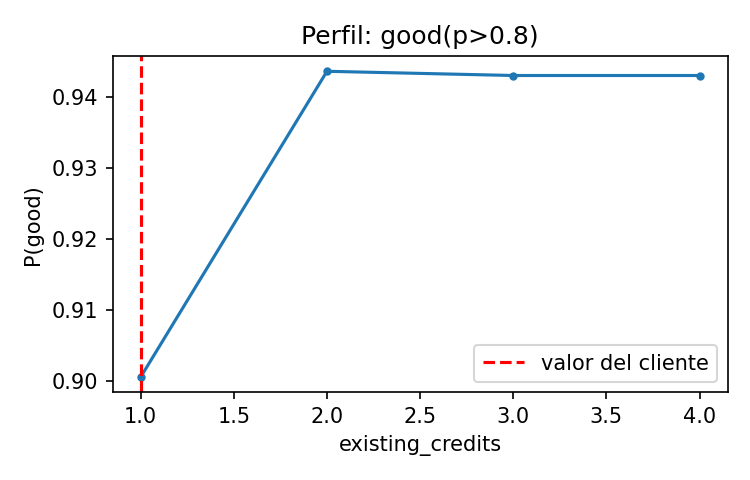

In [22]:
from IPython.display import Image as IPyImage
display(IPyImage(filename=str(DIR / "figuras" / "fig_perfil_discrepancia.png")))

## Resumen numérico de Task 3

In [23]:
for name in CLIENTS:
    t = R3["t31"][name]
    print(f"3.1 {name}: p={t['p']:.3f}  R2_w(K=5)={t['r2_K5']:.4f}  coefs={[(v, round(c, 4)) for v, _, c in t['coefs']]}")
print("3.2 Jaccard:", R3["t32"]["jaccard"])
print("3.2 N_ef:", R3["t32"]["nef"])
for name, t in R3["t33a"].items():
    print(f"3.3a {name}: spearman={t['spearman']:.4f}  overlap top3={t['overlap']}")
print("3.3b R2_w vs K:", {k: round(v, 4) for k, v in R3["t33b"].items()})
print("3.4 validez:", R3["t34"]["validez"], " proximidad:", R3["t34"]["proximidad_media"],
      " dispersion:", R3["t34"]["dispersion_media"])
print("3.5a N*:", R3["t35a"]["N_estimado"], " verificacion:", R3["t35a"]["verificacion"])
print("3.5b:", {k: v for k, v in R3["t35b"].items() if k != "perfil"})

3.1 good(p>0.8): p=0.901  R2_w(K=5)=0.3332  coefs=[('purpose', 0.1721), ('credit_amount', 0.1525), ('checking_status', -0.1144), ('credit_history', -0.113), ('residence_since', 0.0816)]
3.1 rechazado: p=0.103  R2_w(K=5)=0.2080  coefs=[('duration', -0.1508), ('checking_status', -0.1253), ('purpose', -0.1026), ('savings_status', -0.0657), ('age', -0.0581)]
3.1 limite(p~0.5): p=0.504  R2_w(K=5)=0.2791  coefs=[('checking_status', 0.2408), ('duration', -0.1538), ('credit_amount', -0.1064), ('purpose', -0.0736), ('age', 0.0437)]
3.2 Jaccard: {'sig=0.5': {'N=500': 0.6511, 'N=2000': 0.9351, 'N=5000': 1.0}, 'sig=0.75': {'N=500': 0.6145, 'N=2000': 0.9351, 'N=5000': 1.0}, 'sig=1.5': {'N=500': 0.607, 'N=2000': 0.8764, 'N=5000': 1.0}}
3.2 N_ef: {'sig=0.5': {'N=500': 411.5, 'N=2000': 1640.9, 'N=5000': 4103.9}, 'sig=0.75': {'N=500': 480.9, 'N=2000': 1922.6, 'N=5000': 4807.1}, 'sig=1.5': {'N=500': 498.8, 'N=2000': 1995.1, 'N=5000': 4987.7}}
3.3a good(p>0.8): spearman=0.9023  overlap top3=3
3.3a rechaz

# Parte 4 — Task 4: validación de Grad-CAM
Se vuelve a cargar la ResNet-18 con el nombre `cnn` (en las partes 2 y 3 `model` es el gradient boosting). Grad-CAM es el mismo del Task 1.2, escrito a mano con hooks sobre `layer4`; no se usa `pytorch-grad-cam` ni `captum`. Resultados en `resultados/task4.json`. Mismo código que `lab10_task4.py`.

In [24]:
import copy
import json
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image as PILImage
from scipy.stats import spearmanr
from torchvision import models, transforms
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DIR = Path.cwd()
(DIR / "figuras").mkdir(exist_ok=True)
(DIR / "resultados").mkdir(exist_ok=True)

weights = models.ResNet18_Weights.IMAGENET1K_V1
cnn = models.resnet18(weights=weights).eval()
CATS = weights.meta["categories"]
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
geom = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
GRAY = 0.5                                   # gris medio en el espacio de pixeles [0, 1]
IMGS = {"a": "imagenes/img_a_golden.jpg", "b": "imagenes/img_b_gato_perro.jpg", "c": "imagenes/img_c_sofa.jpg"}
img01 = {k: TF.to_tensor(geom(PILImage.open(DIR / p).convert("RGB"))) for k, p in IMGS.items()}   # (3,224,224)
HW = 224 * 224
R4 = {"seed": SEED}


def to_x(im01):
    """Imagen(es) en [0,1] -> entrada normalizada de ImageNet."""
    return TF.normalize(im01, MEAN, STD)


def gradcam_net(net, im01, c):
    """Grad-CAM del Task 1.2 sobre cualquier red con layer4 (hooks temporales).
    alpha_k^c = promedio espacial de dy^c/dA^k ; L^c = ReLU(sum_k alpha_k^c A^k) ; ampliado y min-max."""
    st = {}
    h1 = net.layer4.register_forward_hook(lambda m, i, o: st.__setitem__("A", o))               # A^k_ij
    h2 = net.layer4.register_full_backward_hook(lambda m, gi, go: st.__setitem__("G", go[0]))   # dy^c/dA
    net.zero_grad()
    logits = net(to_x(im01)[None])
    logits[0, c].backward()                       # se retropropaga el LOGIT y^c (antes del softmax)
    h1.remove(); h2.remove()
    A, G = st["A"][0].detach(), st["G"][0].detach()
    alpha = G.mean(dim=(1, 2))                    # alpha_k^c
    raw = (alpha[:, None, None] * A).sum(0)       # sum_k alpha_k^c A^k (sin ReLU)
    L = F.relu(raw)                               # L^c (7x7)
    up = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    up = (up - up.min()) / (up.max() - up.min() + 1e-12)
    return dict(alpha=alpha, raw=raw, L=L, up=up, logits=logits.detach()[0])


@torch.no_grad()
def prob_class(net, ims01, c, bs=32):
    """P(clase c) para un lote de imagenes en [0,1]."""
    return torch.cat([F.softmax(net(to_x(ims01[i:i + bs])), 1)[:, c] for i in range(0, len(ims01), bs)]).numpy()


top1 = {}
maps = {}
for k in IMGS:
    with torch.no_grad():
        top1[k] = int(cnn(to_x(img01[k])[None]).argmax())
    maps[k] = gradcam_net(cnn, img01[k], top1[k])
R4["clases"] = {k: dict(clase=CATS[c], idx=c) for k, c in top1.items()}

## Task 4.1 — Deletion e insertion
Píxeles de $224\times224$ ordenados por el mapa de Grad-CAM (clase top-1), de mayor a menor; los empates (zonas donde el mapa vale 0) se ordenan al azar. En $P=20$ pasos:
- **Deletion:** la fracción $k/P$ de píxeles más importantes se reemplaza por gris medio.
- **Insertion:** se parte de la imagen desenfocada (gaussiano, $\sigma=10$ px) y se insertan los píxeles más importantes de la original.

$$\text{AUC}=\frac1P\sum_{k=1}^{P}c_k,\qquad c_k=P(\text{clase}\mid\text{imagen del paso }k)$$

Se repite con 10 órdenes aleatorios (media y desviación estándar). Diferencia con el azar: $\overline{\text{AUC}}_{rand}-\text{AUC}_{del}$ y $\text{AUC}_{ins}-\overline{\text{AUC}}_{rand}$ (positivo = mejor que el azar); $z$ = esa diferencia en desviaciones estándar del azar. Para el Task 4.3a se repite deletion en la imagen (a) con la imagen desenfocada como referencia en lugar del gris.

In [25]:
P, N_RAND = 20, 10
BLUR_SIGMA, BLUR_KS = 10.0, 61               # desenfoque gaussiano sigma = 10 px (nucleo 2*ceil(3 sigma)+1)
rng4 = np.random.default_rng(SEED)


def map_order(up):
    """Pixeles de mayor a menor valor del mapa. Los empates (zonas donde el mapa vale 0 tras la ReLU)
    se ordenan al azar, para no imponer un orden de barrido por filas."""
    perm = torch.from_numpy(rng4.permutation(HW))
    o = torch.argsort(up.flatten()[perm], descending=True, stable=True)
    return perm[o]


def perturb_curve(base01, src01, order, c):
    """c_k para k = 0..P: la fraccion k/P de pixeles con mayor prioridad (segun `order`) se toma de src01
    y el resto de base01. Deletion: base = imagen, src = gris. Insertion: base = desenfocada, src = imagen."""
    ims = []
    for k in range(P + 1):
        m = torch.zeros(HW, dtype=torch.bool)
        m[order[: int(round(k / P * HW))]] = True
        ims.append(torch.where(m.view(1, 224, 224), src01, base01))
    return prob_class(cnn, torch.stack(ims), c)


def auc(curve):
    """AUC = (1/P) sum_{k=1}^{P} c_k (el punto k=0 no entra)."""
    return float(np.mean(curve[1:]))


R4["t41"] = {}
curves = {}
for k in IMGS:
    x, c = img01[k], top1[k]
    gray = torch.full_like(x, GRAY)
    blur = TF.gaussian_blur(x, kernel_size=BLUR_KS, sigma=BLUR_SIGMA)
    o_map = map_order(maps[k]["up"])
    d_map, i_map = perturb_curve(x, gray, o_map, c), perturb_curve(blur, x, o_map, c)
    d_rnd, i_rnd = [], []
    for _ in range(N_RAND):
        o_r = torch.from_numpy(rng4.permutation(HW))
        d_rnd.append(perturb_curve(x, gray, o_r, c))
        i_rnd.append(perturb_curve(blur, x, o_r, c))
    d_rnd, i_rnd = np.array(d_rnd), np.array(i_rnd)
    ad_r, ai_r = np.array([auc(v) for v in d_rnd]), np.array([auc(v) for v in i_rnd])
    ad, ai = auc(d_map), auc(i_map)
    R4["t41"][k] = dict(
        clase=CATS[c], p_original=float(d_map[0]), p_desenfocada=float(i_map[0]),
        frac_mapa_cero=float((maps[k]["up"] == 0).float().mean()),
        AUC_del=ad, AUC_del_rand_mean=float(ad_r.mean()), AUC_del_rand_std=float(ad_r.std(ddof=1)),
        AUC_ins=ai, AUC_ins_rand_mean=float(ai_r.mean()), AUC_ins_rand_std=float(ai_r.std(ddof=1)),
        dif_del=float(ad_r.mean() - ad), dif_ins=float(ai - ai_r.mean()),          # > 0: mejor que el azar
        z_del=float((ad_r.mean() - ad) / ad_r.std(ddof=1)), z_ins=float((ai - ai_r.mean()) / ai_r.std(ddof=1)),
        curva_del=d_map.tolist(), curva_ins=i_map.tolist(),
        curva_del_rand_mean=d_rnd.mean(0).tolist(), curva_ins_rand_mean=i_rnd.mean(0).tolist())
    curves[k] = dict(d_map=d_map, i_map=i_map, d_rnd=d_rnd, i_rnd=i_rnd)

    # Task 4.3a (solo imagen a): deletion con referencia desenfocada en lugar de gris
    if k == "a":
        db_map = perturb_curve(x, blur, o_map, c)
        db_rnd = np.array([perturb_curve(x, blur, torch.from_numpy(rng4.permutation(HW)), c) for _ in range(N_RAND)])
        adb_r = np.array([auc(v) for v in db_rnd])
        R4["t43a_blur"] = dict(AUC_del_gris=ad, AUC_del_blur=auc(db_map),
                               AUC_del_blur_rand_mean=float(adb_r.mean()), AUC_del_blur_rand_std=float(adb_r.std(ddof=1)),
                               z_del_blur=float((adb_r.mean() - auc(db_map)) / adb_r.std(ddof=1)),
                               curva_del_blur=db_map.tolist(), curva_del_blur_rand_mean=db_rnd.mean(0).tolist())
        curves[k]["db_map"], curves[k]["db_rnd"] = db_map, db_rnd

tabla41 = pd.DataFrame({k: {m: v for m, v in r.items() if not m.startswith("curva") and m != "clase"}
                        for k, r in R4["t41"].items()}).T
print("Task 4.1\n", tabla41.round(4).to_string())
print("Task 4.3a (imagen a, deletion gris vs desenfocada):",
      {m: round(v, 4) for m, v in R4["t43a_blur"].items() if not m.startswith("curva")})

Task 4.1
    p_original  p_desenfocada  frac_mapa_cero  AUC_del  AUC_del_rand_mean  AUC_del_rand_std  AUC_ins  AUC_ins_rand_mean  AUC_ins_rand_std  dif_del  dif_ins     z_del    z_ins
a      0.7795         0.0017          0.0051   0.0636             0.0138            0.0039   0.5706             0.1032            0.0104  -0.0499   0.4674  -12.7534  45.0011
b      0.5130         0.0018          0.1071   0.0065             0.0327            0.0137   0.7415             0.0797            0.0133   0.0263   0.6618    1.9111  49.7803
c      0.3735         0.0002          0.0051   0.0088             0.0002            0.0000   0.1883             0.0348            0.0051  -0.0086   0.1535 -187.3380  30.2275
Task 4.3a (imagen a, deletion gris vs desenfocada): {'AUC_del_gris': 0.0636, 'AUC_del_blur': 0.0827, 'AUC_del_blur_rand_mean': 0.0705, 'AUC_del_blur_rand_std': 0.0141, 'z_del_blur': -0.8674}


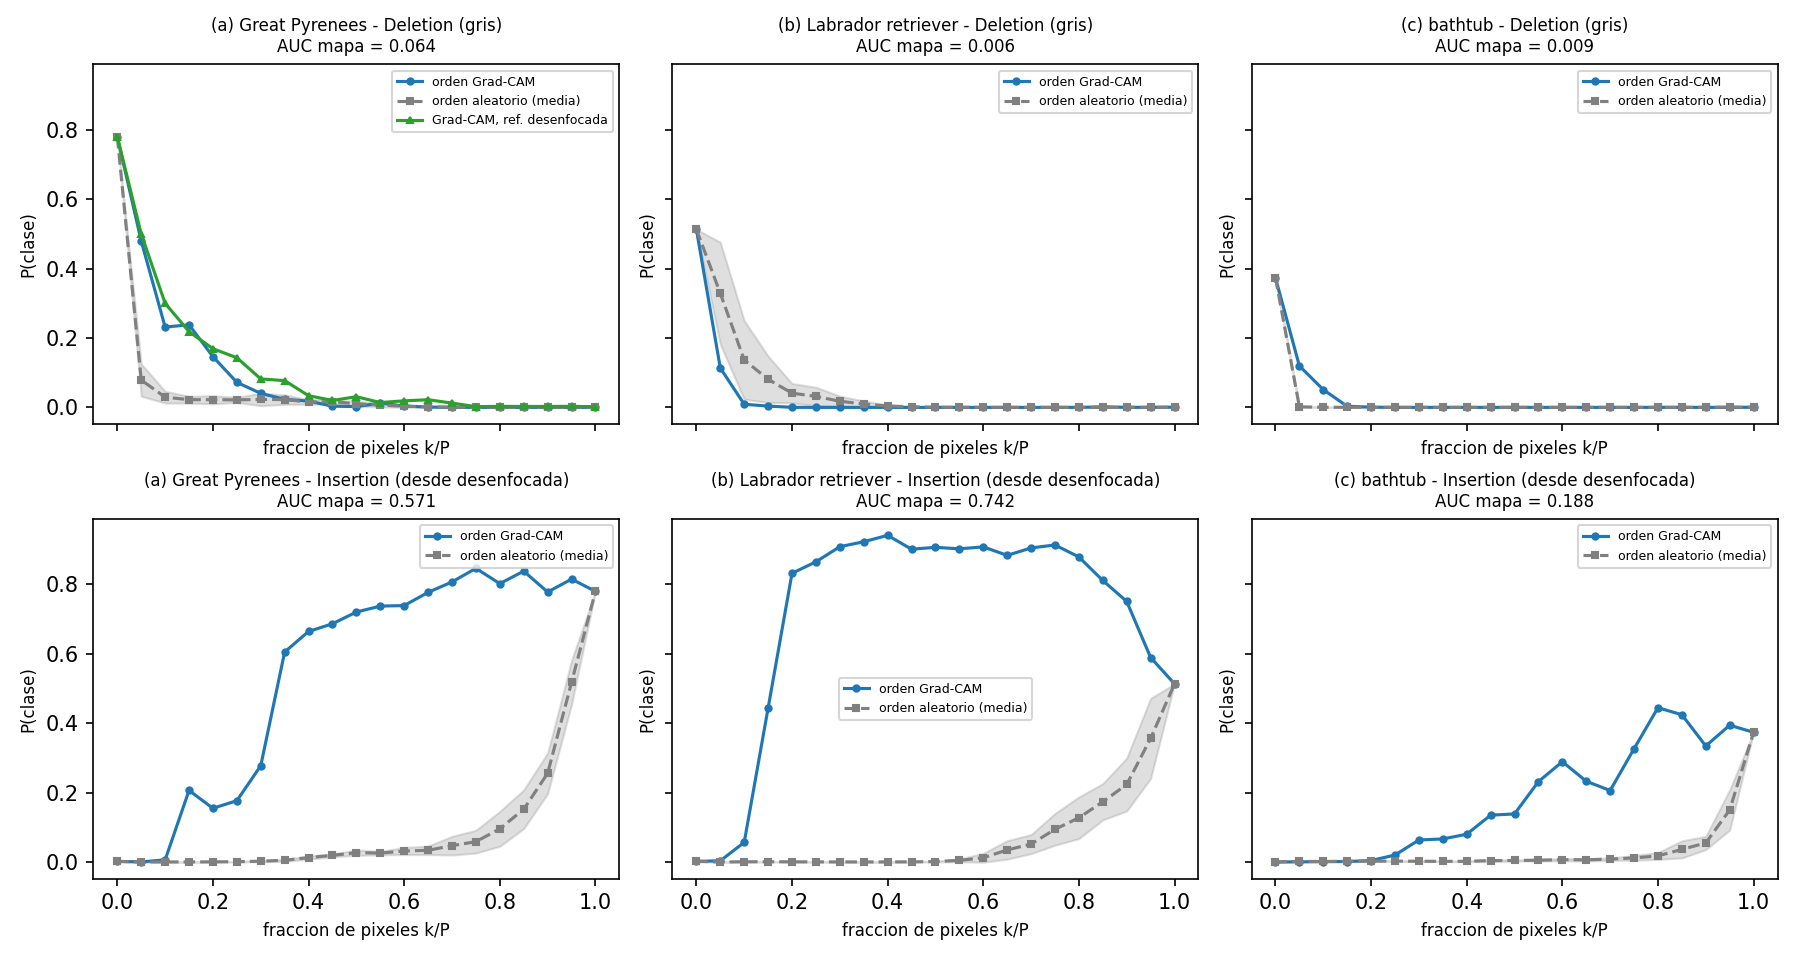

In [26]:
frac = np.arange(P + 1) / P
fig, axs = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for j, k in enumerate(IMGS):
    for i, (key_m, key_r, nombre) in enumerate([("d_map", "d_rnd", "Deletion (gris)"), ("i_map", "i_rnd", "Insertion (desde desenfocada)")]):
        ax, cm, cr = axs[i, j], curves[k][key_m], curves[k][key_r]
        ax.plot(frac, cm, "o-", ms=3, label="orden Grad-CAM")
        ax.plot(frac, cr.mean(0), "s--", ms=3, color="gray", label="orden aleatorio (media)")
        ax.fill_between(frac, cr.mean(0) - cr.std(0, ddof=1), cr.mean(0) + cr.std(0, ddof=1), color="gray", alpha=0.25)
        if k == "a" and i == 0:
            ax.plot(frac, curves[k]["db_map"], "^-", ms=3, color="tab:green", label="Grad-CAM, ref. desenfocada")
        auc_m = R4["t41"][k]["AUC_del" if i == 0 else "AUC_ins"]
        ax.set_title(f"({k}) {CATS[top1[k]][:20]} - {nombre}\nAUC mapa = {auc_m:.3f}", fontsize=8)
        ax.set_xlabel("fraccion de pixeles k/P", fontsize=8)
        ax.set_ylabel("P(clase)", fontsize=8)
        ax.legend(fontsize=6)
plt.tight_layout()
plt.savefig(DIR / "figuras/fig_deletion_insertion.png", dpi=150)
plt.close()

from IPython.display import Image as IPyImage, display
display(IPyImage(filename=str(DIR / "figuras" / "fig_deletion_insertion.png")))

## Task 4.2 — Aleatorización de parámetros en cascada
Etapas acumulativas: `fc`; + `layer4`; + `layer3`; + `layer2`; + `layer1`; + `conv1`. Cada módulo del bloque (Conv2d, BatchNorm2d, Linear) vuelve a la inicialización por defecto de PyTorch (`reset_parameters()`). En cada etapa se calcula el mapa $L^c$ de $7\times7$ para la clase **top-1 del modelo original** y su Spearman con el mapa original. En la etapa `fc` se verifica además que $\alpha^c_k=w^c_k/Z$ con los pesos nuevos.

In [27]:
# Etapas acumulativas: fc; + layer4; + layer3; + layer2; + layer1; + conv1. Cada modulo dentro del bloque
# (Conv2d, BatchNorm2d, Linear) vuelve a la inicializacion por defecto de PyTorch con reset_parameters().
# El mapa se calcula SIEMPRE para la clase top-1 del modelo original, no para la nueva prediccion.
STAGES = ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]


def reinit(block):
    for m in block.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()


def spearman_or_none(u, v):
    """Spearman entre dos mapas 7x7; None si alguno es constante (p. ej. todo cero tras la ReLU)."""
    u, v = u.flatten().numpy(), v.flatten().numpy()
    if np.ptp(u) == 0 or np.ptp(v) == 0:
        return None
    return float(spearmanr(u, v)[0])


torch.manual_seed(SEED)
net = copy.deepcopy(cnn).eval()
casc = {k: [] for k in IMGS}
casc_maps = {k: [maps[k]["L"]] for k in IMGS}
for s in STAGES:
    reinit(getattr(net, s))
    for k in IMGS:
        c = top1[k]
        g = gradcam_net(net, img01[k], c)
        p_new = F.softmax(g["logits"], 0)
        row = dict(etapa=s, spearman=spearman_or_none(maps[k]["L"], g["L"]),
                   spearman_sin_relu=spearman_or_none(maps[k]["raw"], g["raw"]),
                   celdas_positivas=int((g["L"] > 0).sum()),
                   p_clase_original=float(p_new[c]), nueva_top1=CATS[int(p_new.argmax())])
        if s == "fc":   # en la primera etapa alpha^c debe seguir siendo w^c/Z, ahora con los pesos aleatorios
            w_new = net.fc.weight.detach()[c]
            row["max_err_rel_alpha_vs_w_Z"] = float(((g["alpha"] - w_new / 49).abs() / (w_new / 49).abs()).max())
        casc[k].append(row)
        casc_maps[k].append(g["L"])
R4["t42"] = casc
tabla42 = pd.DataFrame({k: {r["etapa"]: r["spearman"] for r in v} for k, v in casc.items()}).T[STAGES]
print("\nTask 4.2 Spearman (mapa 7x7 con ReLU) vs mapa original:\n", tabla42.round(3).to_string())
print("Spearman sin ReLU:\n", pd.DataFrame({k: {r["etapa"]: r["spearman_sin_relu"] for r in v}
                                             for k, v in casc.items()}).T[STAGES].round(3).to_string())

# Task 4.3b: primera etapa con Spearman < 0.3 (un mapa nulo cuenta como sin correlacion)
R4["t43b"] = {k: next((r["etapa"] for r in v if r["spearman"] is None or r["spearman"] < 0.3), None)
              for k, v in casc.items()}
print("Primera etapa con Spearman < 0.3:", R4["t43b"])


Task 4.2 Spearman (mapa 7x7 con ReLU) vs mapa original:
       fc  layer4  layer3  layer2  layer1  conv1
a  0.525   0.250   0.043  -0.154  -0.170 -0.006
b  0.328   0.116   0.036   0.056  -0.173  0.170
c -0.181  -0.055  -0.153   0.250  -0.025 -0.021
Spearman sin ReLU:
       fc  layer4  layer3  layer2  layer1  conv1
a  0.495  -0.143  -0.066   0.042   0.118  0.278
b  0.347   0.123   0.047   0.074  -0.162  0.173
c -0.200   0.244  -0.151   0.204   0.078 -0.020
Primera etapa con Spearman < 0.3: {'a': 'layer4', 'b': 'layer4', 'c': 'fc'}



Listo -> resultados/task4.json


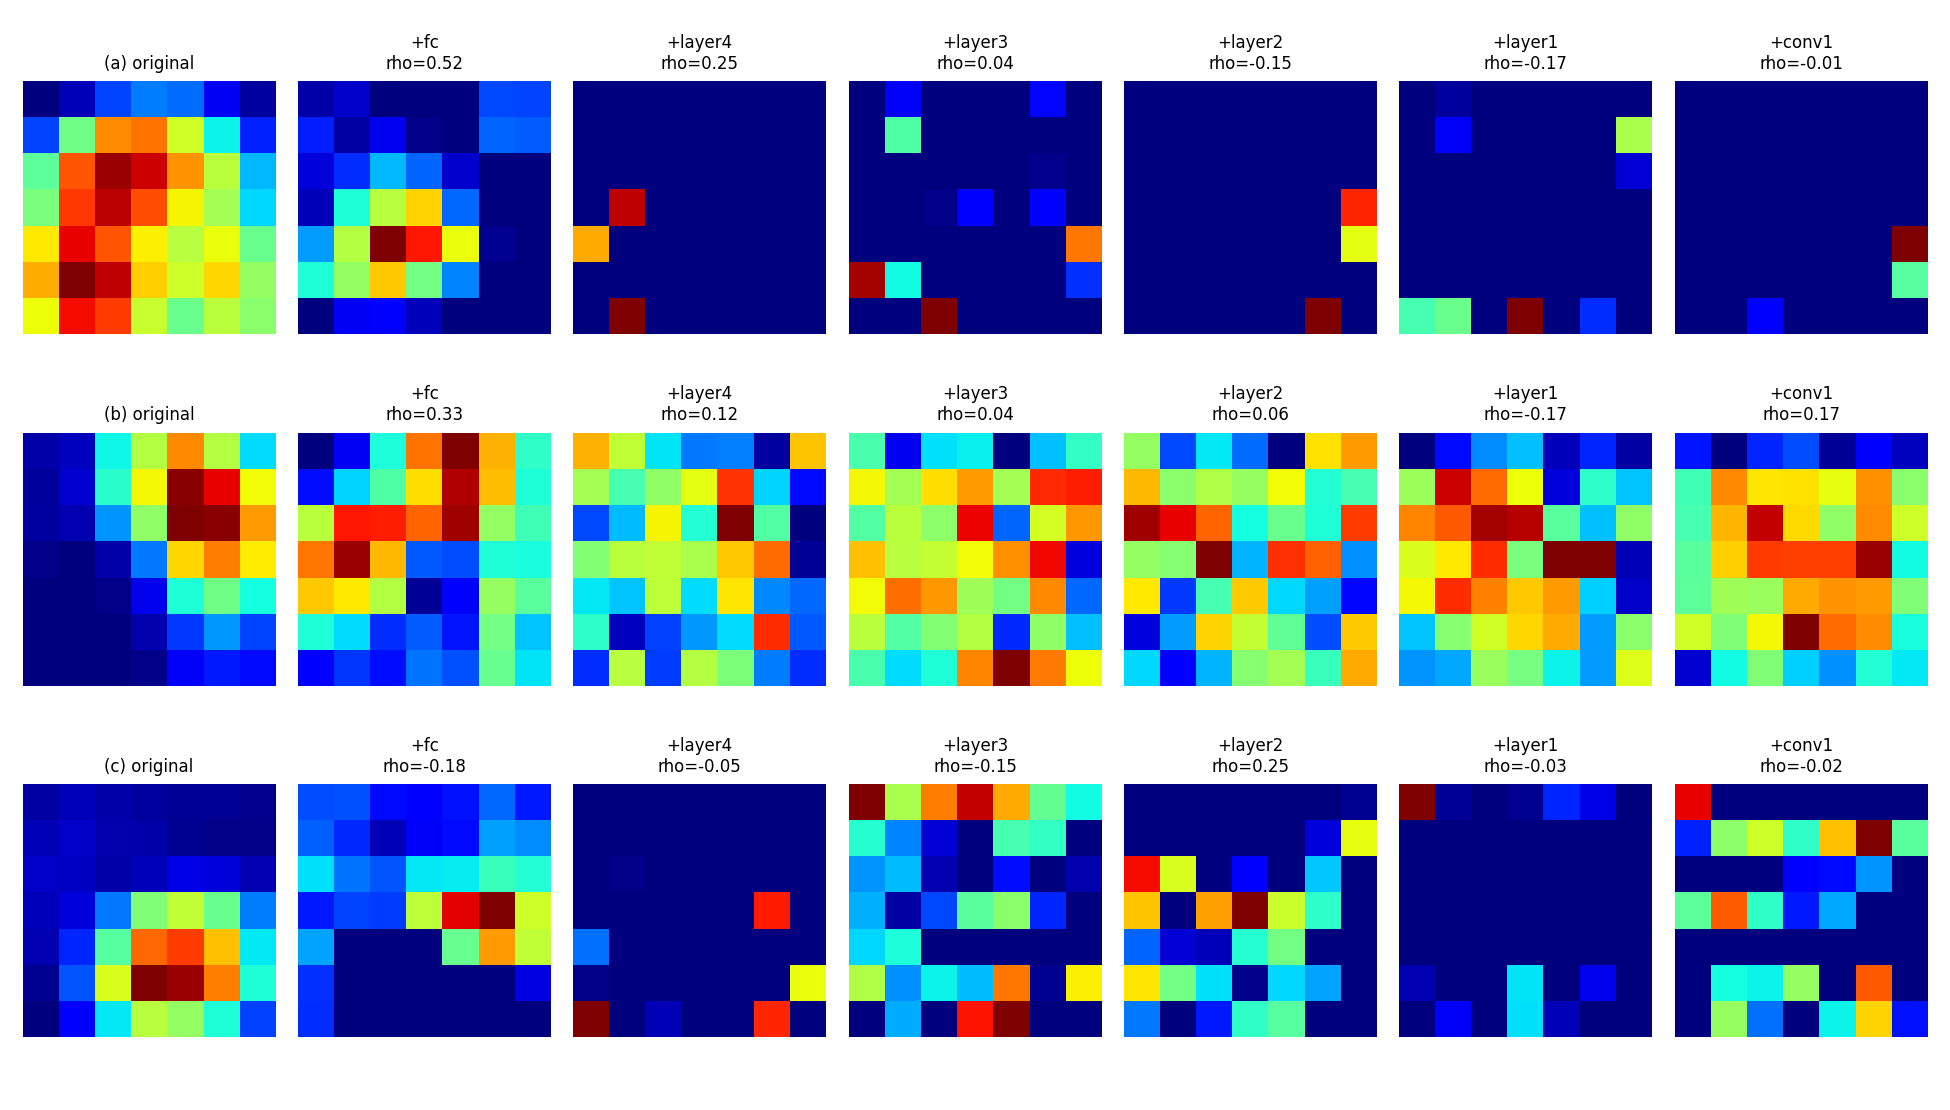

In [28]:
fig, axs = plt.subplots(3, 7, figsize=(13, 7.4))
for i, k in enumerate(IMGS):
    for j, Lm in enumerate(casc_maps[k]):
        ax = axs[i, j]
        rng_m = float(Lm.max() - Lm.min())
        ax.imshow(((Lm - Lm.min()) / rng_m).numpy() if rng_m > 0 else Lm.numpy(), cmap="jet", vmin=0, vmax=1,
                  interpolation="nearest")
        if j == 0:
            ax.set_title(f"({k}) original", fontsize=8)
        else:
            rho = casc[k][j - 1]["spearman"]
            ax.set_title(f"+{STAGES[j - 1]}\nrho={'nulo' if rho is None else f'{rho:.2f}'}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.savefig(DIR / "figuras/fig_cascada.png", dpi=150)
plt.close()
json.dump(R4, open(DIR / "resultados/task4.json", "w"), indent=2, ensure_ascii=False)
print("\nListo -> resultados/task4.json")

display(IPyImage(filename=str(DIR / "figuras" / "fig_cascada.png")))

## Resumen numérico de Task 4

In [29]:
cols = ["AUC_del", "AUC_del_rand_mean", "AUC_del_rand_std", "dif_del", "z_del",
        "AUC_ins", "AUC_ins_rand_mean", "AUC_ins_rand_std", "dif_ins", "z_ins"]
for k in IMGS:
    print(f"4.1 ({k}) {R4['t41'][k]['clase']}:", {c_: round(R4['t41'][k][c_], 4) for c_ in cols})
print("4.3a:", {m: round(v, 4) for m, v in R4["t43a_blur"].items() if not m.startswith("curva")})
print("4.2 Spearman:\n", tabla42.round(3).to_string())
print("4.3b primera etapa con Spearman < 0.3:", R4["t43b"])
print("4.3b error relativo max alpha vs w_nuevo/Z (etapa fc):",
      {k: v[0]["max_err_rel_alpha_vs_w_Z"] for k, v in R4["t42"].items()})

4.1 (a) Great Pyrenees: {'AUC_del': 0.0636, 'AUC_del_rand_mean': 0.0138, 'AUC_del_rand_std': 0.0039, 'dif_del': -0.0499, 'z_del': -12.7534, 'AUC_ins': 0.5706, 'AUC_ins_rand_mean': 0.1032, 'AUC_ins_rand_std': 0.0104, 'dif_ins': 0.4674, 'z_ins': 45.0011}
4.1 (b) Labrador retriever: {'AUC_del': 0.0065, 'AUC_del_rand_mean': 0.0327, 'AUC_del_rand_std': 0.0137, 'dif_del': 0.0263, 'z_del': 1.9111, 'AUC_ins': 0.7415, 'AUC_ins_rand_mean': 0.0797, 'AUC_ins_rand_std': 0.0133, 'dif_ins': 0.6618, 'z_ins': 49.7803}
4.1 (c) bathtub: {'AUC_del': 0.0088, 'AUC_del_rand_mean': 0.0002, 'AUC_del_rand_std': 0.0, 'dif_del': -0.0086, 'z_del': -187.338, 'AUC_ins': 0.1883, 'AUC_ins_rand_mean': 0.0348, 'AUC_ins_rand_std': 0.0051, 'dif_ins': 0.1535, 'z_ins': 30.2275}
4.3a: {'AUC_del_gris': 0.0636, 'AUC_del_blur': 0.0827, 'AUC_del_blur_rand_mean': 0.0705, 'AUC_del_blur_rand_std': 0.0141, 'z_del_blur': -0.8674}
4.2 Spearman:
       fc  layer4  layer3  layer2  layer1  conv1
a  0.525   0.250   0.043  -0.154  -0.170 -

# Uso de IA generativa

Se usó un único prompt para todo el laboratorio (Tasks 1 a 4):

> Actúa como tutor de Deep Learning para mi Laboratorio 9: explicabilidad con Grad-CAM, CAM, SHAP, LIME y contrafactuales. El laboratorio lo hago yo; tu trabajo es guiarme, no resolverlo.
>
> **Contexto**
> - El lab es grupal y pide limitar el uso de IA. Debo documentar cada prompt que use y explicar por qué funcionó.
> - Todo el código es con PyTorch, NumPy y scikit-learn. En los Tasks 1 y 4 no se permite pytorch-grad-cam, captum ni similares. En el Task 2 puedo usar shap, pero la fórmula de Shapley de la 2.5 la escribo yo. En el Task 3 no se permite lime. Uso semilla fija y la reporto.
> - Cada respuesta de análisis debe apoyarse en números y figuras de mi propia ejecución.
>
> **Reglas**
> 1. Trabajamos un subtask a la vez  y esperas a que yo diga "listo" para avanzar.
> 2. No escribas el código completo de ningún subtask ni respondas las preguntas de análisis. Sí puedes explicar la idea en palabras, aclarar una fórmula del enunciado, indicarme qué función o sección de la documentación consultar, y dar fragmentos de máximo 3 a 5 líneas sobre un ejemplo distinto al del lab.
> 3. Ayuda gradual. Primero me haces una pregunta que me oriente. Si me atoro, pista 1 (conceptual), luego pista 2 (qué función o paso usar) y solo después pista 3 (estructura en pseudocódigo). Dime qué nivel de pista estás dando.
> 4. Antes de que ejecute algo, pídeme que prediga qué debería salir: orden de magnitud, signo, qué verificación debe cumplirse. Después comparo mi resultado con mi predicción.
> 5. Cuando pegue mi código, revísalo y señala el error o riesgo (modo eval, hooks, retropropagar desde el logit y no desde el softmax, shapes, semillas) y por qué importa. No lo reescribas completo; dime dónde mirar.
> 6. En las preguntas de análisis (1.4, 2.6, 3.5, 4.3) no escribas la respuesta. Pídeme mis números y mi borrador, y dime qué afirmación no está respaldada por los datos, qué falta y con qué concepto visto en clase debería conectarla.
> 7. Si el enunciado es ambiguo, dime qué decisión debo tomar y justificar. No la tomes por mí.
> 8. Si un resultado me parece raro, ayúdame a diagnosticarlo con preguntas. No inventes ni asumas resultados que no he pegado.
> 9. Respuestas concisas, sin relleno y sin emojis.
>
> Al cerrar cada subtask, dame un registro breve para el PDF: el prompt que usé y 2 o 3 líneas sobre por qué funcionó, es decir, qué parte me orientó sin darme la solución.
>
> Para empezar, pregúntame qué entiendo del Task 1.1 y cuál es mi plan.

**Por qué funcionó.** El prompt fija el papel de la IA como tutor y no como autor, así que las respuestas se limitaron a preguntas, pistas graduales y revisión de nuestro código. Incluir las restricciones del enunciado (sin `pytorch-grad-cam`, `captum` ni `lime`, Shapley escrito a mano, semilla fija) evitó sugerencias que no se podían usar. Pedir una predicción antes de ejecutar y exigir que cada análisis se apoye en nuestros propios números hizo que las verificaciones (eficiencia de SHAP, $\alpha_k^c=w_k^c/Z$, estabilidad de LIME) se interpretaran con datos reales y no con respuestas genéricas.